# 04 — Evaluation & Feature Interpretation: Final Model Comparison, Uncertainty, and Redundancy

**Module Role (`src/evaluate`):** Runs Experiments 23–26 on the fixed 30-day common cohort:
- **Experiment 23:** Final Model Comparison and Paired Bootstrap Uncertainty Analysis
- **Experiment 24:** Modality and Feature Interpretation (Grouped Permutation Importance & Coefficient Stability)
- **Experiment 25:** Feature Importance Verification
- **Experiment 26:** Feature Correlation and Redundancy Analysis

**Run Order:** Step 3 (standalone runnable; saves participant-level OOF predictions used by `05_inference_shap_explainability.ipynb`).


## Setup: Load processed datasets and build fixed 30-day cohort matrices


In [15]:
# Four-dataset analysis script
# Retains the original cohort/model logic and code for Experiments 17-26.
# Earlier exploratory sections (Experiments 1-16), duplicate audit material,
# and the separate correlation/agreement objective (Experiment 27) are omitted.
# Dataset 4 is loaded from its separately prepared processed CSV.
# Dataset 4 experiment counterparts run in an isolated section below.

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the new project's processed data folder.
PROJECT_DIR = None
DATA_DIR = None
for folder in [Path.cwd(), *Path.cwd().parents]:
    for candidate in (folder / "data" / "processed", folder / "processed_data"):
        if candidate.is_dir() and all(
            (candidate / filename).is_file()
            for filename in (
                "dataset1_storyteller.csv",
                "dataset2_ecog.csv",
                "primary_multimodal_30day_cohort.csv",
            )
        ):
            PROJECT_DIR = folder
            DATA_DIR = candidate
            break
    if DATA_DIR is not None:
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find a processed data folder containing the three dataset CSVs."
    )

RESULTS_ROOT = PROJECT_DIR / "results"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# Load the three datasets used by the retained analyses.
dataset1_storyteller = pd.read_csv(
    DATA_DIR / "dataset1_storyteller.csv", low_memory=False
)
dataset2_ecog = pd.read_csv(
    DATA_DIR / "dataset2_ecog.csv", low_memory=False
)
dataset3_multimodal = pd.read_csv(
    DATA_DIR / "primary_multimodal_30day_cohort.csv", low_memory=False
)

# Normalize identifiers and targets without changing cohort membership.
for df in (dataset1_storyteller, dataset2_ecog, dataset3_multimodal):
    if "PTID" not in df or "TARGET" not in df:
        raise KeyError("Each dataset must contain PTID and TARGET columns.")
    df["PTID"] = df["PTID"].astype("string").str.strip()
    df["TARGET"] = pd.to_numeric(df["TARGET"], errors="coerce")
    if df[["PTID", "TARGET"]].isna().any().any():
        raise ValueError("A dataset contains missing PTID or TARGET values.")
    if not df["TARGET"].isin([0, 1]).all():
        raise ValueError("TARGET must contain only 0 and 1.")
    df["TARGET"] = df["TARGET"].astype(int)
    for col in df.columns:
        if "DATE" in str(col).upper():
            df[col] = pd.to_datetime(df[col], errors="coerce")

# Apply the feature exclusions used in the original predictor audit.
STORY_EXCLUDED_TERMS = ("PLAYBACK_COUNT", "GMATCH", "LANGUAGE")
story_feature_cols = [
    col for col in dataset1_storyteller.columns
    if str(col).upper().startswith("STORY")
    and not any(term in str(col).upper() for term in STORY_EXCLUDED_TERMS)
    and col in dataset3_multimodal.columns
]
ecog_feature_cols = [f"ECOGPT{i}" for i in range(1, 13)]

for name, df, features in (
    ("Dataset 1", dataset1_storyteller, story_feature_cols),
    ("Dataset 2", dataset2_ecog, ecog_feature_cols),
    ("Dataset 3", dataset3_multimodal, story_feature_cols + ecog_feature_cols),
):
    missing = [col for col in features if col not in df.columns]
    if missing:
        raise KeyError(f"{name} is missing predictor columns: {missing}")
    for col in features:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Loaded three datasets from:", DATA_DIR)
for name, df in (
    ("Dataset 1 - Storyteller", dataset1_storyteller),
    ("Dataset 2 - ECOG", dataset2_ecog),
    ("Dataset 3 - multimodal", dataset3_multimodal),
):
    print(
        f"{name}: {len(df)} rows, {df['PTID'].nunique()} participants, "
        f"targets={df['TARGET'].value_counts().sort_index().to_dict()}"
    )
print(
    f"Features: {len(story_feature_cols)} Storyteller, "
    f"{len(ecog_feature_cols)} ECOG, "
    f"{len(story_feature_cols) + len(ecog_feature_cols)} fusion"
)


Loaded three datasets from: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\data\processed
Dataset 1 - Storyteller: 1430 rows, 490 participants, targets={0: 1073, 1: 357}
Dataset 2 - ECOG: 501 rows, 397 participants, targets={0: 273, 1: 228}
Dataset 3 - multimodal: 77 rows, 71 participants, targets={0: 53, 1: 24}
Features: 51 Storyteller, 12 ECOG, 63 fusion


In [16]:
# Build the fixed 30-day common cohort and Exp 22 feature matrices
# (Exact deterministic logic from Fixed Cohort Temporal Window Comparison
#  and Nested Participant Grouped Feature Selection — unchanged.)

WINDOWS = {
    "30_days": 30,
    "90_days": 90,
    "180_days": 180,
    "365_days": 365,
    "historical": None,
}

STORY_DATE = "EXAMDATE_STORY"
ECOG_DATE = "COLDATE"
ID_COL = "PTID"
TARGET_COL = "TARGET"

story = dataset1_storyteller.copy()
ecog = dataset2_ecog.copy()

story[STORY_DATE] = pd.to_datetime(story[STORY_DATE], errors="coerce")
ecog[ECOG_DATE] = pd.to_datetime(ecog[ECOG_DATE], errors="coerce")

story = story.dropna(subset=[ID_COL, STORY_DATE, TARGET_COL]).copy()
ecog = ecog.dropna(subset=[ID_COL, ECOG_DATE]).copy()

story[TARGET_COL] = pd.to_numeric(story[TARGET_COL], errors="coerce")
story = story[story[TARGET_COL].isin([0, 1])].copy()

# ECOG value 9 means missing
for col in ecog_feature_cols:
    ecog[col] = pd.to_numeric(ecog[col], errors="coerce")
    ecog[col] = ecog[col].replace(9, np.nan)

ecog = ecog[ecog[ecog_feature_cols].notna().any(axis=1)].copy()

for col in story_feature_cols:
    story[col] = pd.to_numeric(story[col], errors="coerce")

story = story.reset_index(drop=True)
ecog = ecog.reset_index(drop=True)

ecog_by_id = {
    pid: group.sort_values(ECOG_DATE).copy()
    for pid, group in ecog.groupby(ID_COL)
}

eligible_indices = []
for idx, row in story.iterrows():
    pid = row[ID_COL]
    story_date = row[STORY_DATE]
    if pid not in ecog_by_id:
        continue
    participant_ecog = ecog_by_id[pid]
    eligible = participant_ecog[
        (participant_ecog[ECOG_DATE] <= story_date)
        & ((story_date - participant_ecog[ECOG_DATE]).dt.days <= 30)
    ]
    if len(eligible) > 0:
        eligible_indices.append(idx)

common_story = story.loc[eligible_indices].copy().reset_index(drop=True)

window_ecog_data = {}
for window_name, max_days in WINDOWS.items():
    records = []
    for _, row in common_story.iterrows():
        pid = row[ID_COL]
        story_date = row[STORY_DATE]
        participant_ecog = ecog_by_id.get(pid)
        if participant_ecog is None:
            continue
        eligible = participant_ecog[participant_ecog[ECOG_DATE] <= story_date].copy()
        eligible["GAP_DAYS"] = (story_date - eligible[ECOG_DATE]).dt.days
        if max_days is not None:
            eligible = eligible[eligible["GAP_DAYS"] <= max_days]
        if eligible.empty:
            continue
        aggregated = eligible[ecog_feature_cols].median()
        record = {
            "ROW_ID": row.name,
            ID_COL: pid,
            TARGET_COL: row[TARGET_COL],
            "N_ECOG_RECORDS": len(eligible),
            "LATEST_ECOG_GAP": eligible["GAP_DAYS"].min(),
            "OLDEST_ECOG_GAP": eligible["GAP_DAYS"].max(),
        }
        record.update(aggregated.to_dict())
        records.append(record)
    window_ecog_data[window_name] = pd.DataFrame(records)

# Build the exact Exp 22 feature matrices consumed by Experiments 23-26 and SHAP
story22 = common_story.copy().reset_index(drop=True)
ecog22 = window_ecog_data["30_days"].copy().reset_index(drop=True)

if len(story22) != len(ecog22):
    raise ValueError("Storyteller and ECOG row counts do not match.")
if "ROW_ID" in ecog22.columns and ecog22["ROW_ID"].tolist() != list(range(len(story22))):
    raise ValueError("ECOG ROW_ID alignment does not match the cohort.")

X_story22 = story22[story_feature_cols].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)
X_ecog22 = ecog22[ecog_feature_cols].apply(pd.to_numeric, errors="coerce").reset_index(drop=True)
X_full22 = pd.concat([X_story22, X_ecog22], axis=1)
y22 = story22[TARGET_COL].astype(int).to_numpy()
groups22 = story22[ID_COL].to_numpy()

ecog_without_1 = [col for col in ecog_feature_cols if col != "ECOGPT1"]
ecog_without_2 = [col for col in ecog_feature_cols if col != "ECOGPT2"]
ecog_without_1_2 = [col for col in ecog_feature_cols if col not in ["ECOGPT1", "ECOGPT2"]]

candidate_features22 = {
    "Full_fusion": list(story_feature_cols) + list(ecog_feature_cols),
    "Without_ECOGPT1": list(story_feature_cols) + ecog_without_1,
    "Without_ECOGPT2": list(story_feature_cols) + ecog_without_2,
    "Without_ECOGPT1_ECOGPT2": list(story_feature_cols) + ecog_without_1_2,
}

print(
    f"Fixed 30-day cohort ready: {len(story22)} assessments, "
    f"{pd.Series(groups22).nunique()} participants "
    f"(CN={int((y22 == 0).sum())}, MCI={int((y22 == 1).sum())})"
)


Fixed 30-day cohort ready: 77 assessments, 71 participants (CN=53, MCI=24)


## Final Model Comparison and Uncertainty Analysis

Results are saved in results/final_model_comparison_uncertainty/.

In [17]:
# Final Model Comparison and Uncertainty Analysis FINAL MODEL COMPARISON AND UNCERTAINTY ANALYSIS
#
# Primary evaluation:
#   - Participant-level out-of-fold predictions
#   - 5-fold StratifiedGroupKFold
#   - Seed 42 as the pre-specified primary result
#
# Stability evaluation:
#   - 10 random seeds
#   - Same folds for every candidate model within each seed
#
# Uncertainty:
#   - Paired participant-level bootstrap AUC confidence intervals
#   - Bootstrap compares models on the same resampled participants
#   - Intervals condition on these OOF predictions and do not capture all
#     uncertainty from different CV splits or a different cohort
#
# Models:
#   1. Storyteller only
#   2. Full Storyteller + ECOG
#   3. Fusion without ECOGPT1
#   4. Fusion without ECOGPT1 and ECOGPT2
#   5. Fusion without ECOGPT2
#
# No participant is allowed to appear in both train and test.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from collections import defaultdict
import warnings

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PRIMARY_SEED_23 = 42

SEEDS_23 = [11, 21, 42, 52, 62, 72, 82, 92, 102, 112]

N_SPLITS_23 = 5

N_BOOTSTRAP_23 = 2000

THRESHOLD_23 = 0.50

RANDOM_STATE_BOOTSTRAP_23 = 2026

print("=" * 70)
print("Final Model Comparison and Uncertainty Analysis FINAL MODEL COMPARISON")
print("=" * 70)


# ------------------------------------------------------------
# 2. CHECK EXISTING DATA
# ------------------------------------------------------------

required_variables = [
    "X_story22",
    "X_ecog22",
    "X_full22",
    "y22",
    "groups22",
    "candidate_features22"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}. "
        "Run the earlier dataset preparation and Experiment 22 cells first."
    )

X_story23 = X_story22.copy()
X_full23 = X_full22.copy()

y23 = np.asarray(y22).astype(int)
groups23 = np.asarray(groups22)

if not (
    len(X_story23) == len(X_full23) == len(y23) == len(groups23)
):
    raise ValueError("Feature matrices, targets, and groups have different lengths.")

if set(np.unique(y23)) != {0, 1}:
    raise ValueError("Expected binary target: 0 = CN and 1 = MCI.")

print("\nDataset:")
print("Assessments:", len(y23))
print("Participants:", pd.Series(groups23).nunique())
print("CN assessments:", int((y23 == 0).sum()))
print("MCI assessments:", int((y23 == 1).sum()))
print("Storyteller features:", X_story23.shape[1])
print("Full fusion features:", X_full23.shape[1])


# ------------------------------------------------------------
# 3. VERIFY PARTICIPANT DIAGNOSIS CONSISTENCY
# ------------------------------------------------------------

participant_labels23 = pd.DataFrame({
    "PTID": groups23,
    "TARGET": y23
})

label_counts23 = (
    participant_labels23.groupby("PTID")["TARGET"].nunique()
)

inconsistent23 = label_counts23[label_counts23 > 1]

if len(inconsistent23) > 0:
    raise ValueError(
        f"{len(inconsistent23)} participants have inconsistent diagnosis "
        "labels. Resolve this before participant-level evaluation."
    )

participant_table23 = (
    participant_labels23
    .drop_duplicates("PTID")
    .reset_index(drop=True)
)

print("\nParticipant-level diagnosis distribution:")
print(participant_table23["TARGET"].value_counts().sort_index())


# ------------------------------------------------------------
# 4. DEFINE THE FIVE FROZEN MODEL CONFIGURATIONS
# ------------------------------------------------------------

# Use the exact ECOG feature names from the existing matrix.
ecog_items23 = [
    f"ECOGPT{i}" for i in range(1, 13)
]

missing_ecog23 = [
    col for col in ecog_items23
    if col not in X_full23.columns
]

if missing_ecog23:
    raise ValueError(
        "The following ECOG columns are missing from X_full22: "
        f"{missing_ecog23}"
    )

feature_sets23 = {
    "Storyteller only": list(X_story23.columns),

    "Full fusion": list(X_full23.columns),

    "Fusion without ECOGPT1": [
        col for col in X_full23.columns
        if col != "ECOGPT1"
    ],

    "Fusion without ECOGPT1 and ECOGPT2": [
        col for col in X_full23.columns
        if col not in ["ECOGPT1", "ECOGPT2"]
    ],

    "Fusion without ECOGPT2": [
        col for col in X_full23.columns
        if col != "ECOGPT2"
    ]
}

# Verify feature configurations.
for model_name, features in feature_sets23.items():
    if not features:
        raise ValueError(f"{model_name} has no features.")

    missing_cols = [
        col for col in features
        if col not in X_full23.columns
    ]

    if missing_cols:
        raise ValueError(
            f"{model_name} contains missing columns: {missing_cols}"
        )

print("\nFrozen model configurations:")

for model_name, features in feature_sets23.items():
    print(f"{model_name}: {len(features)} features")


# ------------------------------------------------------------
# 5. MODEL PIPELINE
# ------------------------------------------------------------

def create_model23():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            )
        )
    ])


# ------------------------------------------------------------
# 6. PARTICIPANT-LEVEL AGGREGATION
# ------------------------------------------------------------

def aggregate_participant_predictions23(
    y_true,
    participant_ids,
    probabilities
):

    temp = pd.DataFrame({
        "PTID": participant_ids,
        "TARGET": y_true,
        "PROBABILITY": probabilities
    })

    # All assessments belonging to one participant must have
    # the same diagnosis.
    label_check = temp.groupby("PTID")["TARGET"].nunique()

    if (label_check > 1).any():
        raise ValueError(
            "Inconsistent participant labels found during aggregation."
        )

    participant_predictions = (
        temp.groupby("PTID")
        .agg(
            TARGET=("TARGET", "first"),
            PROBABILITY=("PROBABILITY", "mean"),
            N_ASSESSMENTS=("TARGET", "size")
        )
        .reset_index()
    )

    return participant_predictions


# ------------------------------------------------------------
# 7. METRIC CALCULATION
# ------------------------------------------------------------

def calculate_metrics23(y_true, probabilities):

    predictions = (
        np.asarray(probabilities) >= THRESHOLD_23
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    return {
        "Accuracy": accuracy_score(y_true, predictions),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),

        "MCI_Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),

        "MCI_Recall_Sensitivity": recall_score(
            y_true, predictions,
            zero_division=0
        ),

        "Specificity": specificity,

        "MCI_F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_true, probabilities
        ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# ------------------------------------------------------------
# 8. RUN REPEATED GROUPED CROSS-VALIDATION
# ------------------------------------------------------------

# Structure:
# experiment23_predictions[seed][model_name] = participant table

experiment23_predictions = defaultdict(dict)

experiment23_assessment_predictions = defaultdict(dict)

experiment23_fold_results = []

for seed in SEEDS_23:

    print(f"\nRunning seed {seed}...")

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS_23,
        shuffle=True,
        random_state=seed
    )

    # Generate folds once per seed.
    # Every model uses exactly the same train/test participants.
    splits = list(
        cv.split(
            X_full23,
            y23,
            groups=groups23
        )
    )

    # Leakage checks.
    for fold_number, (train_idx, test_idx) in enumerate(splits, 1):

        train_groups = set(groups23[train_idx])
        test_groups = set(groups23[test_idx])

        if train_groups.intersection(test_groups):
            raise RuntimeError(
                f"Participant leakage in seed {seed}, fold {fold_number}"
            )

    for model_name, selected_features in feature_sets23.items():

        oof_probabilities = np.full(
            len(y23),
            np.nan,
            dtype=float
        )

        for fold_number, (train_idx, test_idx) in enumerate(splits, 1):

            X_train = X_full23.iloc[
                train_idx
            ][selected_features]

            X_test = X_full23.iloc[
                test_idx
            ][selected_features]

            y_train = y23[train_idx]

            model = create_model23()

            model.fit(X_train, y_train)

            fold_probabilities = model.predict_proba(
                X_test
            )[:, 1]

            oof_probabilities[test_idx] = fold_probabilities

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                f"Missing OOF predictions for {model_name}, seed {seed}"
            )

        # Save assessment-level OOF predictions.
        assessment_predictions = pd.DataFrame({
            "PTID": groups23,
            "TARGET": y23,
            "PROBABILITY": oof_probabilities
        })

        experiment23_assessment_predictions[
            seed
        ][model_name] = assessment_predictions

        # Primary participant-level predictions.
        participant_predictions = (
            aggregate_participant_predictions23(
                y23,
                groups23,
                oof_probabilities
            )
        )

        experiment23_predictions[
            seed
        ][model_name] = participant_predictions

        metrics = calculate_metrics23(
            participant_predictions["TARGET"],
            participant_predictions["PROBABILITY"]
        )

        experiment23_fold_results.append({
            "Seed": seed,
            "Model": model_name,
            "N_Participants": len(participant_predictions),
            **metrics
        })

print("\nAll repeated grouped CV runs completed.")


# ------------------------------------------------------------
# 9. PRIMARY RESULT: SEED 42
# ------------------------------------------------------------

primary_results23 = pd.DataFrame(
    experiment23_fold_results
)

primary_comparison23 = (
    primary_results23[
        primary_results23["Seed"] == PRIMARY_SEED_23
    ]
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("PRIMARY PARTICIPANT-LEVEL RESULTS: SEED 42")
print("=" * 70)

display(
    primary_comparison23.round(4)
)


# ------------------------------------------------------------
# 10. REPEATED-SEED STABILITY SUMMARY
# ------------------------------------------------------------

stability_metrics23 = [
    "Accuracy",
    "Balanced_Accuracy",
    "MCI_Precision",
    "MCI_Recall_Sensitivity",
    "Specificity",
    "MCI_F1",
    "Macro_F1",
    "ROC_AUC"
]

experiment23_stability = (
    primary_results23
    .groupby("Model")[stability_metrics23]
    .agg(["mean", "std"])
)

print("\n" + "=" * 70)
print("REPEATED-SEED STABILITY: MEAN ± SD")
print("=" * 70)

display(experiment23_stability.round(4))


# ------------------------------------------------------------
# 11. PAIRED PARTICIPANT-LEVEL BOOTSTRAP
#
# Use seed 42 predictions.
#
# Participants are resampled, not assessments.
# The same bootstrap sample is used for both models.
# Stratified resampling preserves the observed number of CN
# and MCI participants in each bootstrap sample.
# ------------------------------------------------------------

rng23 = np.random.default_rng(
    RANDOM_STATE_BOOTSTRAP_23
)

primary_predictions23 = experiment23_predictions[
    PRIMARY_SEED_23
]

reference_model23 = "Full fusion"

reference_table23 = (
    primary_predictions23[reference_model23]
    .sort_values("PTID")
    .reset_index(drop=True)
)

reference_ids23 = reference_table23["PTID"].to_numpy()
reference_y23 = reference_table23["TARGET"].to_numpy()

if len(reference_ids23) != len(np.unique(reference_ids23)):
    raise ValueError("Duplicate participants in primary prediction table.")

class0_idx23 = np.where(reference_y23 == 0)[0]
class1_idx23 = np.where(reference_y23 == 1)[0]

if len(class0_idx23) < 2 or len(class1_idx23) < 2:
    raise ValueError(
        "Insufficient participants in one class for bootstrap AUC."
    )


def paired_bootstrap_auc23(
    y_true,
    reference_probabilities,
    comparison_probabilities,
    n_bootstrap=2000,
    rng=None
):

    if rng is None:
        rng = np.random.default_rng(42)

    y_true = np.asarray(y_true)
    reference_probabilities = np.asarray(reference_probabilities)
    comparison_probabilities = np.asarray(comparison_probabilities)

    class0 = np.where(y_true == 0)[0]
    class1 = np.where(y_true == 1)[0]

    observed_reference = roc_auc_score(
        y_true, reference_probabilities
    )

    observed_comparison = roc_auc_score(
        y_true, comparison_probabilities
    )

    observed_difference = (
        observed_comparison - observed_reference
    )

    bootstrap_reference = []
    bootstrap_comparison = []
    bootstrap_difference = []

    for _ in range(n_bootstrap):

        sampled0 = rng.choice(
            class0,
            size=len(class0),
            replace=True
        )

        sampled1 = rng.choice(
            class1,
            size=len(class1),
            replace=True
        )

        sampled_indices = np.concatenate([
            sampled0,
            sampled1
        ])

        y_sample = y_true[sampled_indices]

        ref_sample = reference_probabilities[
            sampled_indices
        ]

        comp_sample = comparison_probabilities[
            sampled_indices
        ]

        auc_ref = roc_auc_score(
            y_sample, ref_sample
        )

        auc_comp = roc_auc_score(
            y_sample, comp_sample
        )

        bootstrap_reference.append(auc_ref)
        bootstrap_comparison.append(auc_comp)

        bootstrap_difference.append(
            auc_comp - auc_ref
        )

    def ci(values):
        return np.percentile(values, [2.5, 97.5])

    ref_ci = ci(bootstrap_reference)
    comp_ci = ci(bootstrap_comparison)
    diff_ci = ci(bootstrap_difference)

    return {
        "Reference_AUC": observed_reference,
        "Reference_CI_Lower": ref_ci[0],
        "Reference_CI_Upper": ref_ci[1],

        "Comparison_AUC": observed_comparison,
        "Comparison_CI_Lower": comp_ci[0],
        "Comparison_CI_Upper": comp_ci[1],

        "AUC_Difference": observed_difference,
        "Difference_CI_Lower": diff_ci[0],
        "Difference_CI_Upper": diff_ci[1],

        "Bootstrap_Replicates": n_bootstrap
    }


# ------------------------------------------------------------
# 12. RUN PAIRED BOOTSTRAP COMPARISONS
# ------------------------------------------------------------

bootstrap_results23 = []

for model_name, model_table in primary_predictions23.items():

    if model_name == reference_model23:
        continue

    model_table = (
        model_table
        .sort_values("PTID")
        .reset_index(drop=True)
    )

    # Ensure exact participant alignment.
    if not np.array_equal(
        reference_ids23,
        model_table["PTID"].to_numpy()
    ):
        raise ValueError(
            f"Participant alignment mismatch for {model_name}"
        )

    result = paired_bootstrap_auc23(
        y_true=reference_y23,
        reference_probabilities=reference_table23[
            "PROBABILITY"
        ].to_numpy(),
        comparison_probabilities=model_table[
            "PROBABILITY"
        ].to_numpy(),
        n_bootstrap=N_BOOTSTRAP_23,
        rng=rng23
    )

    bootstrap_results23.append({
        "Reference_Model": reference_model23,
        "Comparison_Model": model_name,
        **result
    })

bootstrap_comparison23 = pd.DataFrame(
    bootstrap_results23
)

print("\n" + "=" * 70)
print("PAIRED PARTICIPANT-LEVEL BOOTSTRAP: AUC DIFFERENCES")
print("Difference = comparison model AUC - full fusion AUC")
print("=" * 70)

display(
    bootstrap_comparison23.round(4)
)


# ------------------------------------------------------------
# 13. PRIMARY CONFUSION MATRICES
# ------------------------------------------------------------

confusion_results23 = []

for model_name, table in primary_predictions23.items():

    y_true = table["TARGET"].to_numpy()

    y_pred = (
        table["PROBABILITY"].to_numpy()
        >= THRESHOLD_23
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    confusion_results23.append({
        "Model": model_name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp)
    })

confusion_comparison23 = pd.DataFrame(
    confusion_results23
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX SUMMARY: SEED 42")
print("=" * 70)

display(
    confusion_comparison23.round(4)
)


# ------------------------------------------------------------
# 14. ASSESSMENT-LEVEL SECONDARY RESULTS
# ------------------------------------------------------------

assessment_results23 = []

for model_name, table in experiment23_assessment_predictions[
    PRIMARY_SEED_23
].items():

    metrics = calculate_metrics23(
        table["TARGET"].to_numpy(),
        table["PROBABILITY"].to_numpy()
    )

    assessment_results23.append({
        "Model": model_name,
        "N_Assessments": len(table),
        **metrics
    })

assessment_comparison23 = (
    pd.DataFrame(assessment_results23)
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("SECONDARY ASSESSMENT-LEVEL RESULTS: SEED 42")
print("=" * 70)

display(
    assessment_comparison23.round(4)
)


# ------------------------------------------------------------
# 15. SAVE RESULTS
# ------------------------------------------------------------

from pathlib import Path

RESULTS_DIR_23 = RESULTS_ROOT / "final_model_comparison_uncertainty" / "results"

RESULTS_DIR_23.mkdir(
    parents=True,
    exist_ok=True
)

primary_comparison23.to_csv(
    RESULTS_DIR_23 / "final_model_comparison_uncertainty_primary_participant_results.csv",
    index=False
)

primary_results23.to_csv(
    RESULTS_DIR_23 / "final_model_comparison_uncertainty_all_seed_results.csv",
    index=False
)

experiment23_stability.to_csv(
    RESULTS_DIR_23 / "final_model_comparison_uncertainty_repeated_seed_stability.csv"
)

bootstrap_comparison23.to_csv(
    RESULTS_DIR_23 / "final_model_comparison_uncertainty_paired_bootstrap_auc.csv",
    index=False
)

confusion_comparison23.to_csv(
    RESULTS_DIR_23 / "final_model_comparison_uncertainty_confusion_matrices.csv",
    index=False
)

assessment_comparison23.to_csv(
    RESULTS_DIR_23 / "final_model_comparison_uncertainty_assessment_results.csv",
    index=False
)

# Save participant-level OOF predictions for reproducibility.
for seed, model_dict in experiment23_predictions.items():

    for model_name, table in model_dict.items():

        safe_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("+", "plus")
        )

        table.to_csv(
            RESULTS_DIR_23
            / f"final_model_comparison_uncertainty_seed_{seed}_{safe_name}_participant_predictions.csv",
            index=False
        )

print("\n" + "=" * 70)
print("EXPERIMENT 23 COMPLETED")
print("=" * 70)

print("Results saved to:")
print(RESULTS_DIR_23)

print("\nPrimary model ranking by participant-level AUC:")
display(
    primary_comparison23[
        ["Model", "N_Participants", "ROC_AUC",
         "Balanced_Accuracy", "MCI_Recall_Sensitivity",
         "Specificity"]
    ].round(4)
)



# ============================================================


Final Model Comparison and Uncertainty Analysis FINAL MODEL COMPARISON

Dataset:
Assessments: 77
Participants: 71
CN assessments: 53
MCI assessments: 24
Storyteller features: 51
Full fusion features: 63

Participant-level diagnosis distribution:
TARGET
0    49
1    22
Name: count, dtype: int64

Frozen model configurations:
Storyteller only: 51 features
Full fusion: 63 features
Fusion without ECOGPT1: 62 features
Fusion without ECOGPT1 and ECOGPT2: 61 features
Fusion without ECOGPT2: 62 features

Running seed 11...

Running seed 21...

Running seed 42...

Running seed 52...

Running seed 62...

Running seed 72...

Running seed 82...

Running seed 92...

Running seed 102...

Running seed 112...

All repeated grouped CV runs completed.

PRIMARY PARTICIPANT-LEVEL RESULTS: SEED 42


,Seed,Model,N_Participants,Accuracy,Balanced_Accuracy,MCI_Precision,MCI_Recall_Sensitivity,Specificity,MCI_F1,Macro_F1,ROC_AUC,TN,FP,FN,TP
0,42,Fusion without ECOGPT1 and ECOGPT2,71,0.7746,0.7616,0.6154,0.7273,0.7959,0.6667,0.7482,0.8627,39,10,6,16
1,42,Fusion without ECOGPT2,71,0.7606,0.7514,0.5926,0.7273,0.7755,0.6531,0.7351,0.8516,38,11,6,16
2,42,Fusion without ECOGPT1,71,0.8028,0.7945,0.6538,0.7727,0.8163,0.7083,0.7797,0.8275,40,9,5,17
3,42,Full fusion,71,0.7746,0.7616,0.6154,0.7273,0.7959,0.6667,0.7482,0.8071,39,10,6,16
4,42,Storyteller only,71,0.6479,0.5946,0.4348,0.4545,0.7347,0.4444,0.5934,0.6670,36,13,12,10



REPEATED-SEED STABILITY: MEAN ± SD


Accuracy         Balanced_Accuracy          \
                                       mean     std              mean     std   
Model                                                                           
Full fusion                          0.7592  0.0412            0.7353  0.0502   
Fusion without ECOGPT1               0.7831  0.0327            0.7627  0.0369   
Fusion without ECOGPT1 and ECOGPT2   0.7887  0.0358            0.7668  0.0386   
Fusion without ECOGPT2               0.7746  0.0351            0.7478  0.0411   
Storyteller only                     0.6211  0.0525            0.5840  0.0467   

                                   MCI_Precision          \
                                            mean     std   
Model                                                      
Full fusion                               0.5989  0.0590   
Fusion without ECOGPT1                    0.6356  0.0509   
Fusion without ECOGPT1 and ECOGPT2        0.6474  0.0647   
Fusion without ECOGPT2                    0.6271  0.0549   
Storyteller only                          0.4121  0.0607   

                                   MCI_Recall_Sensitivity         Specificity  \
                                                     mean     std        mean   
Model                                                                           
Full fusion                                        0.6727  0.0767      0.7980   
Fusion without ECOGPT1                             0.7091  0.0575      0.8163   
Fusion without ECOGPT1 and ECOGPT2                 0.7091  0.0575      0.8245   
Fusion without ECOGPT2                             0.6773  0.0659      0.8184   
Storyteller only                                   0.4864  0.0569      0.6816   

                                            MCI_F1         Macro_F1          \
                                       std    mean     std     mean     std   
Model                                                                         
Full fusion                         0.0296  0.6333  0.0654   0.7270  0.0476   
Fusion without ECOGPT1              0.0333  0.6696  0.0478   0.7540  0.0360   
Fusion without ECOGPT1 and ECOGPT2  0.0387  0.6757  0.0527   0.7594  0.0396   
Fusion without ECOGPT2              0.0339  0.6504  0.0551   0.7420  0.0401   
Storyteller only                    0.0695  0.4443  0.0511   0.5779  0.0475   

                                   ROC_AUC          
                                      mean     std  
Model                                               
Full fusion                         0.8235  0.0323  
Fusion without ECOGPT1              0.8403  0.0264  
Fusion without ECOGPT1 and ECOGPT2  0.8569  0.0264  
Fusion without ECOGPT2              0.8418  0.0339  
Storyteller only                    0.6796  0.0344


PAIRED PARTICIPANT-LEVEL BOOTSTRAP: AUC DIFFERENCES
Difference = comparison model AUC - full fusion AUC


,Reference_Model,Comparison_Model,Reference_AUC,Reference_CI_Lower,Reference_CI_Upper,Comparison_AUC,Comparison_CI_Lower,Comparison_CI_Upper,AUC_Difference,Difference_CI_Lower,Difference_CI_Upper,Bootstrap_Replicates
0,Full fusion,Storyteller only,0.8071,0.6892,0.9165,0.6670,0.5111,0.8024,-0.1401,-0.2848,-0.0130,2000
1,Full fusion,Fusion without ECOGPT1,0.8071,0.6827,0.9100,0.8275,0.7031,0.9249,0.0204,-0.0037,0.0529,2000
2,Full fusion,Fusion without ECOGPT1 and ECOGPT2,0.8071,0.6883,0.9109,0.8627,0.7616,0.9462,0.0557,0.0167,0.1058,2000
3,Full fusion,Fusion without ECOGPT2,0.8071,0.6939,0.9082,0.8516,0.7486,0.9397,0.0445,0.0083,0.0900,2000


... (2 outputs left out)


SECONDARY ASSESSMENT-LEVEL RESULTS: SEED 42


,Model,N_Assessments,Accuracy,Balanced_Accuracy,MCI_Precision,MCI_Recall_Sensitivity,Specificity,MCI_F1,Macro_F1,ROC_AUC,TN,FP,FN,TP
0,Fusion without ECOGPT1 and ECOGPT2,77,0.7662,0.7390,0.6154,0.6667,0.8113,0.6400,0.7335,0.8530,43,10,8,16
1,Fusion without ECOGPT2,77,0.7532,0.7296,0.5926,0.6667,0.7925,0.6275,0.7215,0.8436,42,11,8,16
2,Fusion without ECOGPT1,77,0.7922,0.7693,0.6538,0.7083,0.8302,0.6800,0.7631,0.8200,44,9,7,17
3,Full fusion,77,0.7662,0.7390,0.6154,0.6667,0.8113,0.6400,0.7335,0.7972,43,10,8,16
4,Storyteller only,77,0.6623,0.6065,0.4583,0.4583,0.7547,0.4583,0.6065,0.6627,40,13,13,11



EXPERIMENT 23 COMPLETED
Results saved to:
c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\final_model_comparison_uncertainty\results

Primary model ranking by participant-level AUC:


,Model,N_Participants,ROC_AUC,Balanced_Accuracy,MCI_Recall_Sensitivity,Specificity
0,Fusion without ECOGPT1 and ECOGPT2,71,0.8627,0.7616,0.7273,0.7959
1,Fusion without ECOGPT2,71,0.8516,0.7514,0.7273,0.7755
2,Fusion without ECOGPT1,71,0.8275,0.7945,0.7727,0.8163
3,Full fusion,71,0.8071,0.7616,0.7273,0.7959
4,Storyteller only,71,0.6670,0.5946,0.4545,0.7347


## Modality and Feature Interpretation

Results are saved in results/feature_interpretation/.

In [18]:
# Modality and Feature Interpretation FEATURE INTERPRETATION AND MODEL EXPLAINABILITY
#
# Research objectives:
# 1. Identify important Storyteller and ECOG features.
# 2. Measure feature importance using participant-level
#    grouped permutation importance.
# 3. Evaluate logistic regression coefficient stability.
# 4. Compare Storyteller, ECOG, full fusion, and reduced fusion.
#
# Primary model:
#   Storyteller + ECOG, excluding ECOGPT1 and ECOGPT2.
#
# Evaluation:
#   - 5-fold StratifiedGroupKFold
#   - 10 random seeds
#   - Participant-level out-of-fold predictions
#   - Same folds across all modality configurations
#
# Permutation:
#   - Performed on held-out participants only
#   - Participant feature profiles are shuffled together
#   - Participants are shuffled within assessment-count groups
#
# Important:
#   This is exploratory explainability, not external validation.
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from collections import defaultdict

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEEDS_24 = [11, 21, 42, 52, 62, 72, 82, 92, 102, 112]

PRIMARY_SEED_24 = 42

N_SPLITS_24 = 5

N_PERMUTATIONS_24 = 20

THRESHOLD_24 = 0.50

RANDOM_STATE_24 = 2026

print("=" * 75)
print("Modality and Feature Interpretation FEATURE INTERPRETATION")
print("=" * 75)


# ------------------------------------------------------------
# 2. VERIFY EXISTING DATA
# ------------------------------------------------------------

required_variables24 = [
    "X_story22",
    "X_ecog22",
    "X_full22",
    "y22",
    "groups22"
]

missing_variables24 = [
    name for name in required_variables24
    if name not in globals()
]

if missing_variables24:
    raise NameError(
        f"Missing variables: {missing_variables24}. "
        "Run the previous dataset preparation cells first."
    )

X_story24 = X_story22.copy()
X_ecog24 = X_ecog22.copy()
X_full24 = X_full22.copy()

y24 = np.asarray(y22).astype(int)
groups24 = np.asarray(groups22)

if not (
    len(X_story24)
    == len(X_ecog24)
    == len(X_full24)
    == len(y24)
    == len(groups24)
):
    raise ValueError("Dataset lengths do not match.")

if set(np.unique(y24)) != {0, 1}:
    raise ValueError("Expected TARGET values 0=CN and 1=MCI.")

if pd.Series(groups24).nunique() != 71:
    print(
        "WARNING: The current dataset does not contain "
        "exactly 71 participants."
    )

print("\nDataset summary:")
print("Assessments:", len(y24))
print("Participants:", pd.Series(groups24).nunique())
print("CN assessments:", int((y24 == 0).sum()))
print("MCI assessments:", int((y24 == 1).sum()))
print("Storyteller features:", X_story24.shape[1])
print("ECOG features:", X_ecog24.shape[1])
print("Full fusion features:", X_full24.shape[1])


# ------------------------------------------------------------
# 3. VERIFY PARTICIPANT LABEL CONSISTENCY
# ------------------------------------------------------------

participant_check24 = pd.DataFrame({
    "PTID": groups24,
    "TARGET": y24
})

label_counts24 = (
    participant_check24
    .groupby("PTID")["TARGET"]
    .nunique()
)

if (label_counts24 > 1).any():
    raise ValueError(
        "Some participants have inconsistent diagnosis labels. "
        "Resolve these before continuing."
    )

participant_table24 = (
    participant_check24
    .drop_duplicates("PTID")
    .reset_index(drop=True)
)

print("\nParticipant-level diagnosis distribution:")
print(
    participant_table24["TARGET"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 4. DEFINE FEATURE CONFIGURATIONS
# ------------------------------------------------------------

ecog_items24 = [
    f"ECOGPT{i}" for i in range(1, 13)
]

missing_ecog24 = [
    col for col in ecog_items24
    if col not in X_full24.columns
]

if missing_ecog24:
    raise ValueError(
        f"Missing ECOG columns: {missing_ecog24}"
    )

# Confirm Storyteller and ECOG columns are represented
# correctly in the fusion matrix.
if not set(X_story24.columns).issubset(X_full24.columns):
    raise ValueError(
        "Some Storyteller features are missing from fusion."
    )

if not set(X_ecog24.columns).issubset(X_full24.columns):
    raise ValueError(
        "Some ECOG features are missing from fusion."
    )

reduced_features24 = [
    col for col in X_full24.columns
    if col not in ["ECOGPT1", "ECOGPT2"]
]

remaining_ecog24 = [
    col for col in X_ecog24.columns
    if col not in ["ECOGPT1", "ECOGPT2"]
]

feature_sets24 = {
    "Storyteller only": list(X_story24.columns),

    "ECOG only (items 3-12)": remaining_ecog24,

    "Full fusion": list(X_full24.columns),

    "Reduced fusion (without items 1 and 2)": reduced_features24
}

print("\nFeature configurations:")

for model_name, features in feature_sets24.items():
    print(f"{model_name}: {len(features)} features")


# ------------------------------------------------------------
# 5. CREATE MODEL PIPELINE
# ------------------------------------------------------------

def create_model24():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),

        (
            "scaler",
            StandardScaler()
        ),

        (
            "classifier",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            )
        )
    ])


# ------------------------------------------------------------
# 6. PARTICIPANT-LEVEL AGGREGATION
# ------------------------------------------------------------

def aggregate_predictions24(
    y_true,
    participant_ids,
    probabilities
):

    temp = pd.DataFrame({
        "PTID": participant_ids,
        "TARGET": y_true,
        "PROBABILITY": probabilities
    })

    label_counts = (
        temp.groupby("PTID")["TARGET"]
        .nunique()
    )

    if (label_counts > 1).any():
        raise ValueError(
            "Inconsistent participant labels."
        )

    return (
        temp.groupby("PTID")
        .agg(
            TARGET=("TARGET", "first"),
            PROBABILITY=("PROBABILITY", "mean"),
            N_ASSESSMENTS=("TARGET", "size")
        )
        .reset_index()
    )


# ------------------------------------------------------------
# 7. METRIC CALCULATION
# ------------------------------------------------------------

def calculate_metrics24(y_true, probabilities):

    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    predictions = (
        probabilities >= THRESHOLD_24
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    sensitivity = (
        tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    return {
        "Accuracy": accuracy_score(
            y_true, predictions
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_true, predictions
        ),

        "MCI_Precision": precision_score(
            y_true, predictions,
            zero_division=0
        ),

        "MCI_Recall": sensitivity,

        "Specificity": specificity,

        "MCI_F1": f1_score(
            y_true, predictions,
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_true, predictions,
            average="macro",
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_true, probabilities
        ),

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# ------------------------------------------------------------
# 8. MODALITY ABLATION EXPERIMENT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PART 1: MODALITY ABLATION")
print("=" * 75)

modality_predictions24 = defaultdict(dict)

modality_results24 = []

for seed in SEEDS_24:

    print(f"Modality ablation seed: {seed}")

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS_24,
        shuffle=True,
        random_state=seed
    )

    splits = list(
        cv.split(
            X_full24,
            y24,
            groups24
        )
    )

    for model_name, features in feature_sets24.items():

        oof_probabilities = np.full(
            len(y24),
            np.nan
        )

        for train_idx, test_idx in splits:

            if set(groups24[train_idx]).intersection(
                set(groups24[test_idx])
            ):
                raise RuntimeError(
                    "Participant leakage detected."
                )

            model = create_model24()

            model.fit(
                X_full24.iloc[train_idx][features],
                y24[train_idx]
            )

            oof_probabilities[test_idx] = (
                model.predict_proba(
                    X_full24.iloc[test_idx][features]
                )[:, 1]
            )

        if np.isnan(oof_probabilities).any():
            raise RuntimeError(
                f"Missing OOF predictions for {model_name}"
            )

        participant_predictions = aggregate_predictions24(
            y24,
            groups24,
            oof_probabilities
        )

        modality_predictions24[seed][model_name] = (
            participant_predictions
        )

        metrics = calculate_metrics24(
            participant_predictions["TARGET"],
            participant_predictions["PROBABILITY"]
        )

        modality_results24.append({
            "Seed": seed,
            "Model": model_name,
            "N_Participants": len(participant_predictions),
            **metrics
        })


modality_results_df24 = pd.DataFrame(
    modality_results24
)

modality_primary24 = (
    modality_results_df24[
        modality_results_df24["Seed"] == PRIMARY_SEED_24
    ]
    .sort_values("ROC_AUC", ascending=False)
    .reset_index(drop=True)
)

print("\nPrimary modality comparison, seed 42:")
display(modality_primary24.round(4))


modality_stability24 = (
    modality_results_df24
    .groupby("Model")[
        [
            "Accuracy",
            "Balanced_Accuracy",
            "MCI_Recall",
            "Specificity",
            "MCI_F1",
            "ROC_AUC"
        ]
    ]
    .agg(["mean", "std"])
)

print("\nModality comparison across 10 seeds:")
display(modality_stability24.round(4))


# ------------------------------------------------------------
# 9. PARTICIPANT-LEVEL GROUPED PERMUTATION FUNCTION
#
# Permutes complete participant feature profiles.
#
# Participants with different numbers of assessments are
# not exchanged, so each participant's assessment count
# and within-participant feature sequence are preserved.
# ------------------------------------------------------------

def permute_feature_by_participant24(
    X_test,
    test_groups,
    feature,
    rng
):

    X_permuted = X_test.copy()

    test_groups = np.asarray(test_groups)

    # Find assessment positions belonging to each participant.
    participant_positions = {}

    for participant_id in pd.unique(test_groups):

        positions = np.flatnonzero(
            test_groups == participant_id
        )

        participant_positions[participant_id] = positions

    # Group participants by number of assessments.
    count_groups = defaultdict(list)

    for participant_id, positions in participant_positions.items():

        count_groups[len(positions)].append(participant_id)

    feature_position = X_permuted.columns.get_loc(feature)

    for assessment_count, participant_ids in count_groups.items():

        if len(participant_ids) < 2:
            continue

        shuffled_ids = rng.permutation(
            participant_ids
        )

        for destination_id, source_id in zip(
            participant_ids,
            shuffled_ids
        ):

            destination_positions = (
                participant_positions[destination_id]
            )

            source_positions = (
                participant_positions[source_id]
            )

            # Copy the complete feature sequence from another
            # participant with the same assessment count.
            source_values = X_test.iloc[
                source_positions,
                feature_position
            ].to_numpy(copy=True)

            X_permuted.iloc[
                destination_positions,
                feature_position
            ] = source_values

    return X_permuted


# ------------------------------------------------------------
# 10. PERMUTATION IMPORTANCE
#
# Primary configuration:
# Reduced fusion without ECOGPT1 and ECOGPT2.
#
# Importance:
# Baseline held-out participant AUC minus the AUC after
# participant-level permutation of one feature.
#
# Positive importance means that disrupting the feature
# reduced AUC.
#
# Negative importance can occur due to sampling variability
# or potentially unhelpful model reliance.
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PART 2: PARTICIPANT-LEVEL PERMUTATION IMPORTANCE")
print("=" * 75)

permutation_records24 = []

permutation_rng24 = np.random.default_rng(
    RANDOM_STATE_24
)

for seed in SEEDS_24:

    print(f"Permutation importance seed: {seed}")

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS_24,
        shuffle=True,
        random_state=seed
    )

    splits = list(
        cv.split(
            X_full24,
            y24,
            groups24
        )
    )

    for fold_number, (train_idx, test_idx) in enumerate(
        splits, 1
    ):

        X_train = X_full24.iloc[
            train_idx
        ][reduced_features24]

        X_test = X_full24.iloc[
            test_idx
        ][reduced_features24]

        y_train = y24[train_idx]
        y_test = y24[test_idx]

        test_groups = groups24[test_idx]

        model = create_model24()

        model.fit(X_train, y_train)

        baseline_assessment_probabilities = (
            model.predict_proba(X_test)[:, 1]
        )

        baseline_participant = aggregate_predictions24(
            y_test,
            test_groups,
            baseline_assessment_probabilities
        )

        baseline_auc = roc_auc_score(
            baseline_participant["TARGET"],
            baseline_participant["PROBABILITY"]
        )

        # Test-fold participant count.
        n_test_participants = (
            pd.Series(test_groups).nunique()
        )

        for feature in reduced_features24:

            importance_values = []

            for permutation_number in range(
                N_PERMUTATIONS_24
            ):

                X_permuted = (
                    permute_feature_by_participant24(
                        X_test=X_test,
                        test_groups=test_groups,
                        feature=feature,
                        rng=permutation_rng24
                    )
                )

                permuted_probabilities = (
                    model.predict_proba(X_permuted)[:, 1]
                )

                permuted_participant = (
                    aggregate_predictions24(
                        y_test,
                        test_groups,
                        permuted_probabilities
                    )
                )

                permuted_auc = roc_auc_score(
                    permuted_participant["TARGET"],
                    permuted_participant["PROBABILITY"]
                )

                importance_values.append(
                    baseline_auc - permuted_auc
                )

            permutation_records24.append({
                "Seed": seed,
                "Fold": fold_number,
                "Feature": feature,
                "N_Test_Participants": n_test_participants,
                "Baseline_AUC": baseline_auc,
                "Mean_AUC_Drop": np.mean(importance_values),
                "SD_AUC_Drop": np.std(
                    importance_values,
                    ddof=1
                ),
                "Positive_Importance_Frequency": np.mean(
                    np.asarray(importance_values) > 0
                )
            })


permutation_results24 = pd.DataFrame(
    permutation_records24
)

print("\nPermutation importance calculations completed.")


# ------------------------------------------------------------
# 11. FEATURE IMPORTANCE SUMMARY
# ------------------------------------------------------------

feature_importance_summary24 = (
    permutation_results24
    .groupby("Feature")
    .agg(
        Mean_AUC_Drop=("Mean_AUC_Drop", "mean"),
        SD_AUC_Drop=("Mean_AUC_Drop", "std"),
        Mean_Positive_Frequency=(
            "Positive_Importance_Frequency",
            "mean"
        ),
        Mean_Fold_AUC=("Baseline_AUC", "mean"),
        Number_of_Fold_Results=("Mean_AUC_Drop", "count")
    )
    .reset_index()
    .sort_values(
        "Mean_AUC_Drop",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_importance_summary24["Modality"] = (
    feature_importance_summary24["Feature"]
    .apply(
        lambda x: (
            "ECOG" if x.startswith("ECOGPT")
            else "Storyteller"
        )
    )
)

print("\n" + "=" * 75)
print("TOP 20 FEATURES BY PERMUTATION IMPORTANCE")
print("=" * 75)

display(
    feature_importance_summary24.head(20).round(5)
)


# ------------------------------------------------------------
# 12. MODALITY-LEVEL PERMUTATION SUMMARY
# ------------------------------------------------------------

modality_importance_summary24 = (
    feature_importance_summary24
    .groupby("Modality")
    .agg(
        Number_of_Features=("Feature", "count"),
        Mean_Importance=("Mean_AUC_Drop", "mean"),
        Median_Importance=("Mean_AUC_Drop", "median"),
        Positive_Feature_Count=(
            "Mean_Positive_Frequency",
            lambda x: int((x > 0.5).sum())
        )
    )
    .reset_index()
)

print("\nPermutation importance by modality:")
display(modality_importance_summary24.round(5))


# ------------------------------------------------------------
# 13. LOGISTIC REGRESSION COEFFICIENT STABILITY
#
# Coefficients are extracted from the standardized model.
#
# Positive coefficient:
# Higher feature values are associated with higher predicted
# MCI probability, conditional on the other model features.
#
# Negative coefficient:
# Higher feature values are associated with lower predicted
# MCI probability, conditional on the other model features.
#
# These are associations within the fitted model, not causal
# effects or clinical interpretations.
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PART 3: LOGISTIC REGRESSION COEFFICIENT STABILITY")
print("=" * 75)

coefficient_records24 = []

for seed in SEEDS_24:

    print(f"Coefficient analysis seed: {seed}")

    cv = StratifiedGroupKFold(
        n_splits=N_SPLITS_24,
        shuffle=True,
        random_state=seed
    )

    splits = list(
        cv.split(
            X_full24,
            y24,
            groups24
        )
    )

    for fold_number, (train_idx, test_idx) in enumerate(
        splits, 1
    ):

        X_train = X_full24.iloc[
            train_idx
        ][reduced_features24]

        model = create_model24()

        model.fit(
            X_train,
            y24[train_idx]
        )

        classifier = model.named_steps["classifier"]

        coefficients = classifier.coef_[0]

        # SimpleImputer(add_indicator=True) appends missingness
        # indicators after the original input features.
        # Therefore, the first n coefficients correspond to
        # the original feature columns.
        if len(coefficients) < len(reduced_features24):
            raise ValueError(
                "Unexpected coefficient dimension."
            )

        original_coefficients = coefficients[
            :len(reduced_features24)
        ]

        for feature, coefficient in zip(
            reduced_features24,
            original_coefficients
        ):

            coefficient_records24.append({
                "Seed": seed,
                "Fold": fold_number,
                "Feature": feature,
                "Coefficient": coefficient,
                "Absolute_Coefficient": abs(coefficient)
            })


coefficient_results24 = pd.DataFrame(
    coefficient_records24
)

coefficient_summary24 = (
    coefficient_results24
    .groupby("Feature")
    .agg(
        Mean_Coefficient=("Coefficient", "mean"),
        Median_Coefficient=("Coefficient", "median"),
        SD_Coefficient=("Coefficient", "std"),
        Mean_Absolute_Coefficient=(
            "Absolute_Coefficient",
            "mean"
        ),
        Positive_Coefficient_Frequency=(
            "Coefficient",
            lambda x: np.mean(x > 0)
        ),
        Negative_Coefficient_Frequency=(
            "Coefficient",
            lambda x: np.mean(x < 0)
        )
    )
    .reset_index()
    .sort_values(
        "Mean_Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

coefficient_summary24["Modality"] = (
    coefficient_summary24["Feature"]
    .apply(
        lambda x: (
            "ECOG" if x.startswith("ECOGPT")
            else "Storyteller"
        )
    )
)

print("\nTop 20 features by mean absolute standardized coefficient:")
display(
    coefficient_summary24.head(20).round(5)
)


# ------------------------------------------------------------
# 14. COMBINE PERMUTATION AND COEFFICIENT IMPORTANCE
# ------------------------------------------------------------

combined_importance24 = feature_importance_summary24.merge(
    coefficient_summary24,
    on=["Feature", "Modality"],
    how="left"
)

combined_importance24 = combined_importance24.sort_values(
    "Mean_AUC_Drop",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("COMBINED FEATURE INTERPRETATION")
print("=" * 75)

display(
    combined_importance24[
        [
            "Feature",
            "Modality",
            "Mean_AUC_Drop",
            "SD_AUC_Drop",
            "Mean_Positive_Frequency",
            "Mean_Coefficient",
            "Mean_Absolute_Coefficient",
            "Positive_Coefficient_Frequency"
        ]
    ].head(25).round(5)
)


# ------------------------------------------------------------
# 15. IDENTIFY STABLE FEATURES
#
# Exploratory criteria:
# - Positive permutation importance in more than 70% of
#   fold-level permutation results.
# - Positive mean AUC drop.
#
# This is a descriptive stability rule, not a statistical
# significance test.
# ------------------------------------------------------------

stable_features24 = feature_importance_summary24[
    (
        feature_importance_summary24[
            "Mean_Positive_Frequency"
        ] >= 0.70
    )
    &
    (
        feature_importance_summary24[
            "Mean_AUC_Drop"
        ] > 0
    )
].copy()

stable_features24 = stable_features24.sort_values(
    "Mean_AUC_Drop",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("EXPLORATORY STABLE FEATURE LIST")
print("=" * 75)

display(stable_features24.round(5))


# ------------------------------------------------------------
# 16. SAVE RESULTS
# ------------------------------------------------------------

RESULTS_DIR_24 = RESULTS_ROOT / "feature_interpretation" / "results"

RESULTS_DIR_24.mkdir(
    parents=True,
    exist_ok=True
)

modality_results_df24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_modality_all_seeds.csv",
    index=False
)

modality_primary24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_modality_seed42.csv",
    index=False
)

modality_stability24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_modality_stability.csv"
)

permutation_results24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_permutation_fold_results.csv",
    index=False
)

feature_importance_summary24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_feature_importance.csv",
    index=False
)

modality_importance_summary24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_modality_importance.csv",
    index=False
)

coefficient_results24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_coefficients_all_folds.csv",
    index=False
)

coefficient_summary24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_coefficient_stability.csv",
    index=False
)

combined_importance24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_combined_feature_interpretation.csv",
    index=False
)

stable_features24.to_csv(
    RESULTS_DIR_24 / "feature_interpretation_stable_features.csv",
    index=False
)


# ------------------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EXPERIMENT 24 COMPLETED")
print("=" * 75)

print("\nPrimary reduced-fusion model:")
print("Features:", len(reduced_features24))
print("Participants:", pd.Series(groups24).nunique())

print("\nModality stability:")
display(
    modality_stability24.round(4)
)

print("\nTop 10 permutation-important features:")
display(
    feature_importance_summary24.head(10).round(5)
)

print("\nTop 10 coefficient features:")
display(
    coefficient_summary24.head(10).round(5)
)

print("\nExploratory stable features:")
display(
    stable_features24[
        [
            "Feature",
            "Modality",
            "Mean_AUC_Drop",
            "Mean_Positive_Frequency"
        ]
    ].round(5)
)

print("\nAll results saved to:")
print(RESULTS_DIR_24)


# ============================================================


Modality and Feature Interpretation FEATURE INTERPRETATION

Dataset summary:
Assessments: 77
Participants: 71
CN assessments: 53
MCI assessments: 24
Storyteller features: 51
ECOG features: 12
Full fusion features: 63

Participant-level diagnosis distribution:
TARGET
0    49
1    22
Name: count, dtype: int64

Feature configurations:
Storyteller only: 51 features
ECOG only (items 3-12): 10 features
Full fusion: 63 features
Reduced fusion (without items 1 and 2): 61 features

PART 1: MODALITY ABLATION
Modality ablation seed: 11
Modality ablation seed: 21
Modality ablation seed: 42
Modality ablation seed: 52
Modality ablation seed: 62
Modality ablation seed: 72
Modality ablation seed: 82
Modality ablation seed: 92
Modality ablation seed: 102
Modality ablation seed: 112

Primary modality comparison, seed 42:


,Seed,Model,N_Participants,Accuracy,Balanced_Accuracy,MCI_Precision,MCI_Recall,Specificity,MCI_F1,Macro_F1,ROC_AUC,TN,FP,FN,TP
0,42,Reduced fusion (without items 1 and 2),71,0.7746,0.7616,0.6154,0.7273,0.7959,0.6667,0.7482,0.8627,39,10,6,16
1,42,Full fusion,71,0.7746,0.7616,0.6154,0.7273,0.7959,0.6667,0.7482,0.8071,39,10,6,16
2,42,ECOG only (items 3-12),71,0.7887,0.7342,0.6842,0.5909,0.8776,0.6341,0.7428,0.7560,43,6,9,13
3,42,Storyteller only,71,0.6479,0.5946,0.4348,0.4545,0.7347,0.4444,0.5934,0.6670,36,13,12,10



Modality comparison across 10 seeds:


Accuracy         Balanced_Accuracy  \
                                           mean     std              mean   
Model                                                                       
ECOG only (items 3-12)                   0.7394  0.0313            0.6973   
Full fusion                              0.7592  0.0412            0.7353   
Reduced fusion (without items 1 and 2)   0.7887  0.0358            0.7668   
Storyteller only                         0.6211  0.0525            0.5840   

                                               MCI_Recall         Specificity  \
                                           std       mean     std        mean   
Model                                                                           
ECOG only (items 3-12)                  0.0334     0.5864  0.0500      0.8082   
Full fusion                             0.0502     0.6727  0.0767      0.7980   
Reduced fusion (without items 1 and 2)  0.0386     0.7091  0.0575      0.8245   
Storyteller only                        0.0467     0.4864  0.0569      0.6816   

                                                MCI_F1         ROC_AUC          
                                           std    mean     std    mean     std  
Model                                                                           
ECOG only (items 3-12)                  0.0350  0.5826  0.0452  0.7340  0.0259  
Full fusion                             0.0296  0.6333  0.0654  0.8235  0.0323  
Reduced fusion (without items 1 and 2)  0.0387  0.6757  0.0527  0.8569  0.0264  
Storyteller only                        0.0695  0.4443  0.0511  0.6796  0.0344


PART 2: PARTICIPANT-LEVEL PERMUTATION IMPORTANCE
Permutation importance seed: 11
Permutation importance seed: 21
Permutation importance seed: 42
Permutation importance seed: 52
Permutation importance seed: 62
Permutation importance seed: 72
Permutation importance seed: 82
Permutation importance seed: 92
Permutation importance seed: 102
Permutation importance seed: 112

Permutation importance calculations completed.

TOP 20 FEATURES BY PERMUTATION IMPORTANCE


,Feature,Mean_AUC_Drop,SD_AUC_Drop,Mean_Positive_Frequency,Mean_Fold_AUC,Number_of_Fold_Results,Modality
0,ECOGPT8,0.10930,0.06771,0.864,0.86059,50,ECOG
1,STORY2IMM_MEAN_PAUSE_LENGTH,0.09554,0.06782,0.848,0.86059,50,Storyteller
2,ECOGPT10,0.03932,0.04695,0.662,0.86059,50,ECOG
3,STORY1IMM_IDEA_DENSITY,0.03577,0.03946,0.651,0.86059,50,Storyteller
4,ECOGPT5,0.03475,0.03346,0.583,0.86059,50,ECOG
5,STORY1DEL_MEAN_LETTER_PER_WORD,0.02957,0.03622,0.624,0.86059,50,Storyteller
6,STORY1DEL_ARTICULATION_RATE,0.02705,0.03127,0.589,0.86059,50,Storyteller
7,ECOGPT9,0.02420,0.03767,0.570,0.86059,50,ECOG
8,STORY1DEL_NUM_PROPER_NOUNS,0.02369,0.03880,0.546,0.86059,50,Storyteller
9,STORY1IMM_AUDIO_LENGTH,0.02333,0.04316,0.560,0.86059,50,Storyteller


... (13 outputs left out)

,Feature,Mean_Coefficient,Median_Coefficient,SD_Coefficient,Mean_Absolute_Coefficient,Positive_Coefficient_Frequency,Negative_Coefficient_Frequency,Modality
0,ECOGPT8,1.07141,1.08880,0.14932,1.07141,1.0,0.0,ECOG
1,STORY2IMM_MEAN_PAUSE_LENGTH,1.05053,1.07812,0.17476,1.05053,1.0,0.0,Storyteller
2,ECOGPT9,-0.73846,-0.78279,0.19193,0.73846,0.0,1.0,ECOG
3,STORY1IMM_IDEA_DENSITY,0.62932,0.61326,0.12077,0.62932,1.0,0.0,Storyteller
4,ECOGPT5,-0.60467,-0.60082,0.13110,0.60467,0.0,1.0,ECOG
5,STORY2IMM_NUM_PAUSES,-0.59430,-0.60029,0.12604,0.59430,0.0,1.0,Storyteller
6,ECOGPT10,0.55246,0.54063,0.20571,0.55246,1.0,0.0,ECOG
7,STORY1IMM_MEAN_LETTER_PER_WORD,-0.52636,-0.53999,0.13353,0.52636,0.0,1.0,Storyteller
8,STORY1DEL_MEAN_LETTER_PER_WORD,-0.51323,-0.51847,0.17002,0.51323,0.0,1.0,Storyteller
9,STORY1IMM_AUDIO_LENGTH,0.51159,0.51678,0.09310,0.51159,1.0,0.0,Storyteller



Exploratory stable features:


,Feature,Modality,Mean_AUC_Drop,Mean_Positive_Frequency
0,ECOGPT8,ECOG,0.10930,0.864
1,STORY2IMM_MEAN_PAUSE_LENGTH,Storyteller,0.09554,0.848



All results saved to:
c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_interpretation\results


## Feature Importance Verification

Results are saved in results/feature_importance_verification/.

In [19]:
# Feature Importance Verification FEATURE IMPORTANCE VERIFICATION
# CORRECTED VERSION
#
# Objectives:
# 1. Correctly aggregate Experiment 24 permutation results.
# 2. Use the existing within-fold positive permutation frequency.
# 3. Audit baseline AUC consistency.
# 4. Compare permutation importance with coefficient stability.
# 5. Prepare an ECOG item interpretation template.
#
# Uses existing Experiment 24 variables.
# No dataset reload required.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

print("=" * 75)
print("Feature Importance Verification FEATURE IMPORTANCE VERIFICATION")
print("=" * 75)


# ------------------------------------------------------------
# PART 0: CONFIGURATION AND INPUT CHECKS
# ------------------------------------------------------------

RESULTS_DIR = RESULTS_ROOT / "feature_importance_verification"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

required_variables = [
    "permutation_records24",
    "coefficient_results24"
]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"Required variable '{variable}' is missing. "
            "Run Experiment 24 first."
        )

perm_raw25 = permutation_records24.copy()
coef_raw25 = coefficient_results24.copy()

if not isinstance(perm_raw25, pd.DataFrame):
    perm_raw25 = pd.DataFrame(perm_raw25)

if not isinstance(coef_raw25, pd.DataFrame):
    coef_raw25 = pd.DataFrame(coef_raw25)

print("\nInput dimensions:")
print("Permutation records:", perm_raw25.shape)
print("Coefficient records:", coef_raw25.shape)

print("\nPermutation columns:")
print(perm_raw25.columns.tolist())

print("\nCoefficient columns:")
print(coef_raw25.columns.tolist())


# ------------------------------------------------------------
# PART 1: COLUMN IDENTIFICATION
# ------------------------------------------------------------

def find_column(df, candidates, required=True):
    """Find a column using possible column-name aliases."""

    lookup = {
        str(col).lower().replace(" ", "_"): col
        for col in df.columns
    }

    for candidate in candidates:
        key = candidate.lower().replace(" ", "_")
        if key in lookup:
            return lookup[key]

    if required:
        raise ValueError(
            f"Could not find any of these columns: {candidates}\n"
            f"Available columns: {df.columns.tolist()}"
        )

    return None


# Permutation columns
feature_col25 = find_column(
    perm_raw25,
    ["Feature", "feature", "Feature_Name"]
)

drop_col25 = find_column(
    perm_raw25,
    ["Mean_AUC_Drop", "AUC_Drop", "Importance",
     "Permutation_Importance"]
)

baseline_col25 = find_column(
    perm_raw25,
    ["Baseline_AUC", "Base_AUC", "Original_AUC",
     "Fold_AUC"],
    required=False
)

positive_perm_col25 = find_column(
    perm_raw25,
    [
        "Positive_Importance_Frequency",
        "Positive_Frequency",
        "Positive_Permutation_Frequency",
        "Permutation_Positive_Frequency"
    ],
    required=False
)

seed_col25 = find_column(
    perm_raw25,
    ["Seed", "Random_State"],
    required=False
)

fold_col25 = find_column(
    perm_raw25,
    ["Fold", "Fold_Number", "Split"],
    required=False
)

print("\nIdentified permutation columns:")
print("Feature:", feature_col25)
print("Mean AUC drop:", drop_col25)
print("Baseline AUC:", baseline_col25)
print("Positive permutation frequency:", positive_perm_col25)
print("Seed:", seed_col25)
print("Fold:", fold_col25)


# ------------------------------------------------------------
# PART 2: PREPARE PERMUTATION RECORDS
# ------------------------------------------------------------

perm25 = perm_raw25.copy()

perm25[drop_col25] = pd.to_numeric(
    perm25[drop_col25],
    errors="coerce"
)

if baseline_col25 is not None:
    perm25[baseline_col25] = pd.to_numeric(
        perm25[baseline_col25],
        errors="coerce"
    )

if positive_perm_col25 is not None:
    perm25[positive_perm_col25] = pd.to_numeric(
        perm25[positive_perm_col25],
        errors="coerce"
    )

perm25[feature_col25] = perm25[feature_col25].astype(str)

perm25 = perm25.dropna(
    subset=[feature_col25, drop_col25]
).copy()

print("\nFirst five permutation records:")
display(perm25.head())


# ------------------------------------------------------------
# PART 3: CORRECT FOLD-LEVEL PERMUTATION AGGREGATION
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CORRECTED PERMUTATION IMPORTANCE AGGREGATION")
print("=" * 75)

fold_columns25 = []

if seed_col25 is not None:
    fold_columns25.append(seed_col25)

if fold_col25 is not None:
    fold_columns25.append(fold_col25)


# IMPORTANT:
# Experiment 24 already aggregated individual permutations
# within each feature/fold.
#
# Therefore:
# - Mean_AUC_Drop is the fold-level mean AUC decrease.
# - Positive_Importance_Frequency is the within-fold
#   proportion of permutations that produced a positive AUC drop.
#
# We must NOT calculate the permutation-positive frequency
# from whether Mean_AUC_Drop itself is positive.


if positive_perm_col25 is not None:

    print(
        "Using the existing Positive_Importance_Frequency "
        "from Experiment 24."
    )

    perm25["Positive_Frequency_Used25"] = (
        perm25[positive_perm_col25].clip(0, 1)
    )

    positive_frequency_source25 = (
        "Existing within-fold permutation frequency"
    )

else:

    print(
        "WARNING: No within-fold positive permutation "
        "frequency column was found."
    )

    print(
        "Using the proportion of positive fold-level mean "
        "AUC drops as a fallback. This is NOT the same as "
        "the proportion of positive individual permutations."
    )

    perm25["Positive_Frequency_Used25"] = (
        perm25[drop_col25] > 0
    ).astype(float)

    positive_frequency_source25 = (
        "Fallback: proportion of positive fold-level mean AUC drops"
    )


if fold_columns25:

    # One row per seed, fold and feature after this aggregation.
    fold_importance25 = (
        perm25
        .groupby(
            fold_columns25 + [feature_col25],
            dropna=False
        )
        .agg(
            Fold_Mean_AUC_Drop=(drop_col25, "mean"),
            Fold_SD_AUC_Drop=(drop_col25, "std"),
            Fold_Positive_Frequency=(
                "Positive_Frequency_Used25", "mean"
            ),
            Number_of_Input_Records=(drop_col25, "count")
        )
        .reset_index()
    )

    permutation_summary25 = (
        fold_importance25
        .groupby(feature_col25)
        .agg(
            Mean_AUC_Drop=("Fold_Mean_AUC_Drop", "mean"),
            SD_AUC_Drop=("Fold_Mean_AUC_Drop", "std"),
            Mean_Positive_Frequency=(
                "Fold_Positive_Frequency", "mean"
            ),
            Number_of_Fold_Results=(
                "Fold_Mean_AUC_Drop", "count"
            )
        )
        .reset_index()
        .rename(columns={feature_col25: "Feature"})
        .sort_values("Mean_AUC_Drop", ascending=False)
        .reset_index(drop=True)
    )

else:

    print(
        "WARNING: Seed/fold identifiers are unavailable. "
        "Only overall aggregation is possible."
    )

    fold_importance25 = None

    permutation_summary25 = (
        perm25
        .groupby(feature_col25)
        .agg(
            Mean_AUC_Drop=(drop_col25, "mean"),
            SD_AUC_Drop=(drop_col25, "std"),
            Mean_Positive_Frequency=(
                "Positive_Frequency_Used25", "mean"
            ),
            Number_of_Fold_Results=(drop_col25, "count")
        )
        .reset_index()
        .rename(columns={feature_col25: "Feature"})
        .sort_values("Mean_AUC_Drop", ascending=False)
        .reset_index(drop=True)
    )


permutation_summary25["Positive_Frequency_Source"] = (
    positive_frequency_source25
)

print("\nCorrected permutation importance:")
display(permutation_summary25.head(25))


# ------------------------------------------------------------
# PART 4: BASELINE AUC CONSISTENCY AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("BASELINE AUC CONSISTENCY AUDIT")
print("=" * 75)

baseline_by_fold25 = None

if baseline_col25 is not None:

    print(
        "\nOverall baseline AUC mean:",
        round(perm25[baseline_col25].mean(), 5)
    )

    print(
        "Overall baseline AUC SD:",
        round(perm25[baseline_col25].std(), 5)
    )

    print(
        "Unique baseline AUC values:",
        perm25[baseline_col25].nunique()
    )

    if fold_columns25:

        baseline_by_fold25 = (
            perm25
            .groupby(fold_columns25)[baseline_col25]
            .agg(["mean", "std", "min", "max", "count"])
            .reset_index()
        )

        baseline_by_fold25["Baseline_AUC_Spread"] = (
            baseline_by_fold25["max"]
            - baseline_by_fold25["min"]
        )

        print("\nBaseline AUC by seed and fold:")
        display(baseline_by_fold25)

        maximum_spread25 = (
            baseline_by_fold25["Baseline_AUC_Spread"].max()
        )

        print(
            "\nMaximum baseline AUC spread within a fold:",
            round(maximum_spread25, 10)
        )

        if maximum_spread25 < 1e-8:
            print(
                "PASS: Baseline AUC is constant across "
                "feature permutations within each fold."
            )
        else:
            print(
                "CHECK: Baseline AUC varies within at least "
                "one fold. Inspect the raw records."
            )

else:
    print(
        "No baseline AUC column was found. "
        "The baseline cannot be independently audited."
    )


# ------------------------------------------------------------
# PART 5: COEFFICIENT STABILITY AUDIT
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COEFFICIENT STABILITY AUDIT")
print("=" * 75)

coef_feature_col25 = find_column(
    coef_raw25,
    ["Feature", "feature", "Feature_Name"]
)

coef_value_col25 = find_column(
    coef_raw25,
    [
        "Coefficient",
        "Standardized_Coefficient",
        "Coefficient_Value"
    ]
)

coef_raw25[coef_value_col25] = pd.to_numeric(
    coef_raw25[coef_value_col25],
    errors="coerce"
)

coef_raw25[coef_feature_col25] = (
    coef_raw25[coef_feature_col25].astype(str)
)

coef_raw25 = coef_raw25.dropna(
    subset=[coef_feature_col25, coef_value_col25]
).copy()


coefficient_summary25 = (
    coef_raw25
    .groupby(coef_feature_col25)
    .agg(
        Mean_Coefficient=(coef_value_col25, "mean"),
        Median_Coefficient=(coef_value_col25, "median"),
        SD_Coefficient=(coef_value_col25, "std"),
        Mean_Absolute_Coefficient=(
            coef_value_col25,
            lambda x: np.abs(x).mean()
        ),
        Positive_Coefficient_Frequency=(
            coef_value_col25,
            lambda x: (x > 0).mean()
        ),
        Negative_Coefficient_Frequency=(
            coef_value_col25,
            lambda x: (x < 0).mean()
        ),
        Number_of_Coefficient_Results=(
            coef_value_col25, "count"
        )
    )
    .reset_index()
    .rename(columns={coef_feature_col25: "Feature"})
)

print("\nTop 20 features by mean absolute coefficient:")

display(
    coefficient_summary25
    .sort_values(
        "Mean_Absolute_Coefficient",
        ascending=False
    )
    .head(20)
)


# ------------------------------------------------------------
# PART 6: COMBINE PERMUTATION AND COEFFICIENT RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("COMBINED FEATURE IMPORTANCE AUDIT")
print("=" * 75)

combined_audit25 = permutation_summary25.merge(
    coefficient_summary25,
    on="Feature",
    how="outer"
)

combined_audit25["Modality"] = np.where(
    combined_audit25["Feature"].str.startswith("ECOGPT"),
    "ECOG",
    "Storyteller"
)

combined_audit25 = combined_audit25.sort_values(
    "Mean_AUC_Drop",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

display(combined_audit25.head(25))


# ------------------------------------------------------------
# PART 7: EXPLORATORY FEATURE CONSISTENCY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FEATURE CONSISTENCY ANALYSIS")
print("=" * 75)

# Descriptive criteria:
# 1. Positive mean permutation AUC drop.
# 2. Positive permutation frequency >= 70%.
# 3. Coefficient direction consistent in >= 80% of results.
#
# These are exploratory screening criteria, not statistical tests.


positive_coefficient25 = (
    combined_audit25[
        "Positive_Coefficient_Frequency"
    ].fillna(0) >= 0.80
)

negative_coefficient25 = (
    combined_audit25[
        "Negative_Coefficient_Frequency"
    ].fillna(0) >= 0.80
)

consistent_direction25 = (
    positive_coefficient25 | negative_coefficient25
)

positive_auc_drop25 = (
    combined_audit25["Mean_AUC_Drop"].fillna(-np.inf) > 0
)

positive_permutation_frequency25 = (
    combined_audit25[
        "Mean_Positive_Frequency"
    ].fillna(0) >= 0.70
)

stable_features25 = combined_audit25.loc[
    positive_auc_drop25
    & positive_permutation_frequency25
    & consistent_direction25
].copy()

print(
    "Features meeting the exploratory consistency criteria:",
    len(stable_features25)
)

display(
    stable_features25[
        [
            "Feature",
            "Modality",
            "Mean_AUC_Drop",
            "SD_AUC_Drop",
            "Mean_Positive_Frequency",
            "Mean_Coefficient",
            "Positive_Coefficient_Frequency",
            "Negative_Coefficient_Frequency"
        ]
    ]
)


# ------------------------------------------------------------
# PART 8: ECOG ITEM DESCRIPTION TEMPLATE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ECOG ITEM METADATA INSPECTION")
print("=" * 75)

# Search already-loaded datasets for potential metadata.
# Do not invent questionnaire descriptions.

candidate_dataframes25 = {}

for name in [
    "dataset2_ecog",
    "dataset3_multimodal",
    "ecog_full",
    "ecog22",
    "ecog_participant"
]:

    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        candidate_dataframes25[name] = obj


for name, df in candidate_dataframes25.items():

    relevant_columns = [
        col for col in df.columns
        if (
            "ECOG" in str(col).upper()
            or "LABEL" in str(col).upper()
            or "DESCRIPTION" in str(col).upper()
            or "QUESTION" in str(col).upper()
        )
    ]

    print(f"\n{name}:")
    print("Relevant columns:", relevant_columns)

    if relevant_columns:
        display(df[relevant_columns].head(3))


ecog_item_descriptions25 = {
    f"ECOGPT{i}": ""
    for i in range(1, 13)
}

ecog_metadata25 = pd.DataFrame([
    {
        "Feature": feature,
        "Official_Item_Description": description,
        "Scoring_Direction_Verified": "Not yet verified",
        "Interpretation": (
            "Pending official ECOG-PT questionnaire review"
        )
    }
    for feature, description
    in ecog_item_descriptions25.items()
])

print("\nECOG item description template:")
display(ecog_metadata25)


# ------------------------------------------------------------
# PART 9: FINAL FEATURE INTERPRETATION TABLE
# ------------------------------------------------------------

final_interpretation25 = combined_audit25.merge(
    ecog_metadata25[
        [
            "Feature",
            "Official_Item_Description",
            "Scoring_Direction_Verified"
        ]
    ],
    on="Feature",
    how="left"
)

final_interpretation25["Interpretation_Status"] = np.where(
    final_interpretation25["Modality"] == "ECOG",
    "Questionnaire wording and scoring require verification",
    "Speech-feature definition should be checked"
)

print("\n" + "=" * 75)
print("FINAL FEATURE INTERPRETATION TABLE")
print("=" * 75)

display(final_interpretation25.head(25))


# ------------------------------------------------------------
# PART 10: SAVE RESULTS
# ------------------------------------------------------------

output_files25 = {
    "feature_importance_verification_permutation_summary.csv":
        permutation_summary25,

    "feature_importance_verification_coefficient_summary.csv":
        coefficient_summary25,

    "feature_importance_verification_combined_importance.csv":
        combined_audit25,

    "feature_importance_verification_stable_features.csv":
        stable_features25,

    "feature_importance_verification_ecog_metadata_template.csv":
        ecog_metadata25,

    "feature_importance_verification_final_interpretation.csv":
        final_interpretation25
}

if fold_importance25 is not None:
    output_files25[
        "feature_importance_verification_fold_level_permutation.csv"
    ] = fold_importance25

if baseline_by_fold25 is not None:
    output_files25[
        "feature_importance_verification_baseline_auc_audit.csv"
    ] = baseline_by_fold25


for filename, dataframe in output_files25.items():

    save_path = RESULTS_DIR / filename

    dataframe.to_csv(
        save_path,
        index=False
    )

    print("Saved:", save_path)


# ------------------------------------------------------------
# PART 11: FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("EXPERIMENT 25 COMPLETED")
print("=" * 75)

print(
    "Permutation features audited:",
    permutation_summary25["Feature"].nunique()
)

print(
    "Coefficient features audited:",
    coefficient_summary25["Feature"].nunique()
)

print(
    "Combined features:",
    combined_audit25["Feature"].nunique()
)

print(
    "Features meeting exploratory consistency criteria:",
    len(stable_features25)
)

print(
    "\nPositive-frequency calculation:",
    positive_frequency_source25
)

print("\nTop 10 features:")

display(
    combined_audit25[
        [
            "Feature",
            "Mean_AUC_Drop",
            "SD_AUC_Drop",
            "Mean_Positive_Frequency",
            "Mean_Absolute_Coefficient"
        ]
    ].head(10)
)

print("\nResults directory:")
print(RESULTS_DIR)

print("\nIMPORTANT INTERPRETATION NOTES:")
print(
    "1. Permutation importance is based on held-out fold predictions."
)
print(
    "2. Positive frequency is averaged from the existing "
    "within-fold permutation frequencies."
)
print(
    "3. Coefficients describe associations in the fitted "
    "standardized logistic regression models."
)
print(
    "4. Repeated CV folds/seeds are not independent external "
    "validation samples."
)
print(
    "5. ECOG item wording and scoring direction must be checked "
    "against the official questionnaire before assigning "
    "clinical meaning."
)
print(
    "6. Feature importance does not establish causality or "
    "clinical diagnostic value."
)

print("\nEXPERIMENT 25 FINISHED SUCCESSFULLY.")


# ============================================================


Feature Importance Verification FEATURE IMPORTANCE VERIFICATION

Input dimensions:
Permutation records: (3050, 8)
Coefficient records: (3050, 5)

Permutation columns:
['Seed', 'Fold', 'Feature', 'N_Test_Participants', 'Baseline_AUC', 'Mean_AUC_Drop', 'SD_AUC_Drop', 'Positive_Importance_Frequency']

Coefficient columns:
['Seed', 'Fold', 'Feature', 'Coefficient', 'Absolute_Coefficient']

Identified permutation columns:
Feature: Feature
Mean AUC drop: Mean_AUC_Drop
Baseline AUC: Baseline_AUC
Positive permutation frequency: Positive_Importance_Frequency
Seed: Seed
Fold: Fold

First five permutation records:


,Seed,Fold,Feature,N_Test_Participants,Baseline_AUC,Mean_AUC_Drop,SD_AUC_Drop,Positive_Importance_Frequency
0,11,1,STORY1IMM_AUDIO_LENGTH,15,0.98,-0.001,0.015183,0.25
1,11,1,STORY1IMM_NUM_PRONOUNS,15,0.98,-0.006,0.009403,0.00
2,11,1,STORY1IMM_NUM_NOUNS,15,0.98,-0.003,0.007327,0.00
3,11,1,STORY1IMM_NUM_PROPER_NOUNS,15,0.98,0.002,0.006156,0.10
4,11,1,STORY1IMM_NUM_VERBS,15,0.98,0.000,0.006489,0.05



CORRECTED PERMUTATION IMPORTANCE AGGREGATION
Using the existing Positive_Importance_Frequency from Experiment 24.

Corrected permutation importance:


,Feature,Mean_AUC_Drop,SD_AUC_Drop,Mean_Positive_Frequency,Number_of_Fold_Results,Positive_Frequency_Source
0,ECOGPT8,0.109301,0.067706,0.864,50,Existing within-fold permutation frequency
1,STORY2IMM_MEAN_PAUSE_LENGTH,0.095543,0.067823,0.848,50,Existing within-fold permutation frequency
2,ECOGPT10,0.039322,0.046951,0.662,50,Existing within-fold permutation frequency
3,STORY1IMM_IDEA_DENSITY,0.035768,0.039455,0.651,50,Existing within-fold permutation frequency
4,ECOGPT5,0.034751,0.033459,0.583,50,Existing within-fold permutation frequency
5,STORY1DEL_MEAN_LETTER_PER_WORD,0.029568,0.036218,0.624,50,Existing within-fold permutation frequency
6,STORY1DEL_ARTICULATION_RATE,0.027047,0.031267,0.589,50,Existing within-fold permutation frequency
7,ECOGPT9,0.024204,0.037673,0.570,50,Existing within-fold permutation frequency
8,STORY1DEL_NUM_PROPER_NOUNS,0.023692,0.038798,0.546,50,Existing within-fold permutation frequency
9,STORY1IMM_AUDIO_LENGTH,0.023331,0.043158,0.560,50,Existing within-fold permutation frequency



BASELINE AUC CONSISTENCY AUDIT

Overall baseline AUC mean: 0.86059
Overall baseline AUC SD: 0.09147
Unique baseline AUC values: 35

Baseline AUC by seed and fold:


,Seed,Fold,mean,std,min,max,count,Baseline_AUC_Spread
0,11,1,0.980000,0.0,0.980000,0.980000,61,0.0
1,11,2,0.833333,0.0,0.833333,0.833333,61,0.0
2,11,3,0.733333,0.0,0.733333,0.733333,61,0.0
3,11,4,0.772727,0.0,0.772727,0.772727,61,0.0
4,11,5,0.900000,0.0,0.900000,0.900000,61,0.0
5,21,1,0.777778,0.0,0.777778,0.777778,61,0.0
6,21,2,0.933333,0.0,0.933333,0.933333,61,0.0
7,21,3,0.800000,0.0,0.800000,0.800000,61,0.0
8,21,4,0.775000,0.0,0.775000,0.775000,61,0.0
9,21,5,0.939394,0.0,0.939394,0.939394,61,0.0


... (15 outputs left out)

,Feature,Mean_AUC_Drop,SD_AUC_Drop,Mean_Positive_Frequency,Number_of_Fold_Results,Positive_Frequency_Source,Mean_Coefficient,Median_Coefficient,SD_Coefficient,Mean_Absolute_Coefficient,Positive_Coefficient_Frequency,Negative_Coefficient_Frequency,Number_of_Coefficient_Results,Modality,Official_Item_Description,Scoring_Direction_Verified,Interpretation_Status
0,ECOGPT8,0.109301,0.067706,0.864,50,Existing within-fold permutation frequency,1.071407,1.088797,0.149321,1.071407,1.00,0.00,50,ECOG,,Not yet verified,Questionnaire wording and scoring require veri...
1,STORY2IMM_MEAN_PAUSE_LENGTH,0.095543,0.067823,0.848,50,Existing within-fold permutation frequency,1.050533,1.078116,0.174758,1.050533,1.00,0.00,50,Storyteller,NaN,NaN,Speech-feature definition should be checked
2,ECOGPT10,0.039322,0.046951,0.662,50,Existing within-fold permutation frequency,0.552460,0.540627,0.205709,0.552460,1.00,0.00,50,ECOG,,Not yet verified,Questionnaire wording and scoring require veri...
3,STORY1IMM_IDEA_DENSITY,0.035768,0.039455,0.651,50,Existing within-fold permutation frequency,0.629317,0.613261,0.120767,0.629317,1.00,0.00,50,Storyteller,NaN,NaN,Speech-feature definition should be checked
4,ECOGPT5,0.034751,0.033459,0.583,50,Existing within-fold permutation frequency,-0.604668,-0.600818,0.131099,0.604668,0.00,1.00,50,ECOG,,Not yet verified,Questionnaire wording and scoring require veri...
5,STORY1DEL_MEAN_LETTER_PER_WORD,0.029568,0.036218,0.624,50,Existing within-fold permutation frequency,-0.513227,-0.518474,0.170017,0.513227,0.00,1.00,50,Storyteller,NaN,NaN,Speech-feature definition should be checked
6,STORY1DEL_ARTICULATION_RATE,0.027047,0.031267,0.589,50,Existing within-fold permutation frequency,0.433211,0.430580,0.101283,0.433211,1.00,0.00,50,Storyteller,NaN,NaN,Speech-feature definition should be checked
7,ECOGPT9,0.024204,0.037673,0.570,50,Existing within-fold permutation frequency,-0.738465,-0.782790,0.191929,0.738465,0.00,1.00,50,ECOG,,Not yet verified,Questionnaire wording and scoring require veri...
8,STORY1DEL_NUM_PROPER_NOUNS,0.023692,0.038798,0.546,50,Existing within-fold permutation frequency,-0.466868,-0.468449,0.134937,0.466868,0.00,1.00,50,Storyteller,NaN,NaN,Speech-feature definition should be checked
9,STORY1IMM_AUDIO_LENGTH,0.023331,0.043158,0.560,50,Existing within-fold permutation frequency,0.511595,0.516784,0.093102,0.511595,1.00,0.00,50,Storyteller,NaN,NaN,Speech-feature definition should be checked


Saved: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification\feature_importance_verification_permutation_summary.csv
Saved: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification\feature_importance_verification_coefficient_summary.csv
Saved: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification\feature_importance_verification_combined_importance.csv
Saved: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification\feature_importance_verification_stable_features.csv
Saved: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification\feature_importance_verification_ecog_metadata_template.csv
Saved: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification\feature_importance_verification_final_interpretation.csv
Save

,Feature,Mean_AUC_Drop,SD_AUC_Drop,Mean_Positive_Frequency,Mean_Absolute_Coefficient
0,ECOGPT8,0.109301,0.067706,0.864,1.071407
1,STORY2IMM_MEAN_PAUSE_LENGTH,0.095543,0.067823,0.848,1.050533
2,ECOGPT10,0.039322,0.046951,0.662,0.552460
3,STORY1IMM_IDEA_DENSITY,0.035768,0.039455,0.651,0.629317
4,ECOGPT5,0.034751,0.033459,0.583,0.604668
5,STORY1DEL_MEAN_LETTER_PER_WORD,0.029568,0.036218,0.624,0.513227
6,STORY1DEL_ARTICULATION_RATE,0.027047,0.031267,0.589,0.433211
7,ECOGPT9,0.024204,0.037673,0.570,0.738465
8,STORY1DEL_NUM_PROPER_NOUNS,0.023692,0.038798,0.546,0.466868
9,STORY1IMM_AUDIO_LENGTH,0.023331,0.043158,0.560,0.511595



Results directory:
c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_importance_verification

IMPORTANT INTERPRETATION NOTES:
1. Permutation importance is based on held-out fold predictions.
2. Positive frequency is averaged from the existing within-fold permutation frequencies.
3. Coefficients describe associations in the fitted standardized logistic regression models.
4. Repeated CV folds/seeds are not independent external validation samples.
5. ECOG item wording and scoring direction must be checked against the official questionnaire before assigning clinical meaning.
6. Feature importance does not establish causality or clinical diagnostic value.

EXPERIMENT 25 FINISHED SUCCESSFULLY.


## Feature Correlation and Redundancy Analysis

Results are saved in results/feature_correlation_redundancy/.

Feature Correlation and Redundancy Analysis INITIAL DATA AUDIT
Storyteller assessment rows: 77
ECOG assessment rows: 77
Unique participants: 71
Storyteller features: 51
ECOG features: 12

Participant-level feature matrix:
(71, 63)
Participants with inconsistent labels: 0

FEATURE MISSINGNESS AND VARIABILITY


,Feature,Modality,Missing_Count,Missing_Percentage,Unique_Values,Standard_Deviation,Constant_Feature
51,ECOGPT1,ECOG,1,1.408451,5,0.926630,False
55,ECOGPT5,ECOG,1,1.408451,4,0.611696,False
57,ECOGPT7,ECOG,1,1.408451,3,0.362873,False
60,ECOGPT10,ECOG,1,1.408451,4,0.598307,False
52,ECOGPT2,ECOG,0,0.000000,6,0.788244,False
...,...,...,...,...,...,...,...
46,STORY1DEL_NONSPEECH_PROPORTION,Storyteller,0,0.000000,67,0.183920,False
47,STORY1DEL_SPEECH_RATE,Storyteller,0,0.000000,71,0.624252,False
48,STORY1DEL_ARTICULATION_RATE,Storyteller,0,0.000000,70,0.497878,False
49,STORY1DEL_NUM_PAUSES,Storyteller,0,0.000000,20,4.544537,False



Feature Correlation and Redundancy Analysis CORRELATION RESULTS

Total valid feature pairs: 1953
Storyteller-Storyteller pairs: 1275
ECOG-ECOG pairs: 66
Storyteller-ECOG pairs: 612

Pairs with absolute Spearman correlation >= 0.7: 99

TOP 20 CORRELATED FEATURE PAIRS


,Feature_1,Feature_2,Analysis_Type,N_Participants,Pearson_r,Spearman_rho,Spearman_FDR
1233,STORY1DEL_NUM_WORDS,STORY1DEL_SPEECH_DURATION,Storyteller-Storyteller,71,0.963129,0.956139,3.131034e-35
332,STORY1IMM_NUM_WORDS,STORY1IMM_SPEECH_DURATION,Storyteller-Storyteller,71,0.944879,0.933399,1.878689e-29
1199,STORY1DEL_NUM_VERBS,STORY1DEL_NUM_WORDS,Storyteller-Storyteller,71,0.929307,0.932650,1.878689e-29
55,STORY1IMM_NUM_PRONOUNS,STORY1IMM_NUM_WORDS,Storyteller-Storyteller,71,0.926429,0.929643,6.044987e-29
103,STORY1IMM_NUM_NOUNS,STORY1IMM_NUM_WORDS,Storyteller-Storyteller,71,0.925752,0.923328,8.435289e-28
196,STORY1IMM_NUM_VERBS,STORY1IMM_NUM_WORDS,Storyteller-Storyteller,71,0.928635,0.922628,8.807965e-28
1160,STORY1DEL_NUM_PRONOUNS,STORY1DEL_NUM_WORDS,Storyteller-Storyteller,71,0.913207,0.922446,8.807965e-28
927,STORY2IMM_NUM_WORDS,STORY2IMM_SPEECH_DURATION,Storyteller-Storyteller,71,0.908788,0.915519,1.311756e-26
783,STORY2IMM_NUM_NOUNS,STORY2IMM_NUM_WORDS,Storyteller-Storyteller,71,0.921393,0.908654,1.536618e-25
1174,STORY1DEL_NUM_NOUNS,STORY1DEL_NUM_WORDS,Storyteller-Storyteller,71,0.918519,0.907191,2.333991e-25



HIGH CROSS-MODAL CORRELATIONS


,Feature_1,Feature_2,N_Participants,Pearson_r,Spearman_rho,Spearman_FDR



FEATURE-LEVEL CORRELATION SUMMARY


,Feature,Modality,Number_Highly_Correlated_Pairs,Strongest_Absolute_Spearman
41,STORY1DEL_NUM_WORDS,Storyteller,15,0.956139
45,STORY1DEL_SPEECH_DURATION,Storyteller,14,0.956139
1,STORY1IMM_NUM_PRONOUNS,Storyteller,13,0.929643
7,STORY1IMM_NUM_WORDS,Storyteller,12,0.933399
36,STORY1DEL_NUM_NOUNS,Storyteller,12,0.907191
...,...,...,...,...
56,ECOGPT6,ECOG,0,0.000000
58,ECOGPT8,ECOG,0,0.000000
57,ECOGPT7,ECOG,0,0.000000
60,ECOGPT10,ECOG,0,0.000000


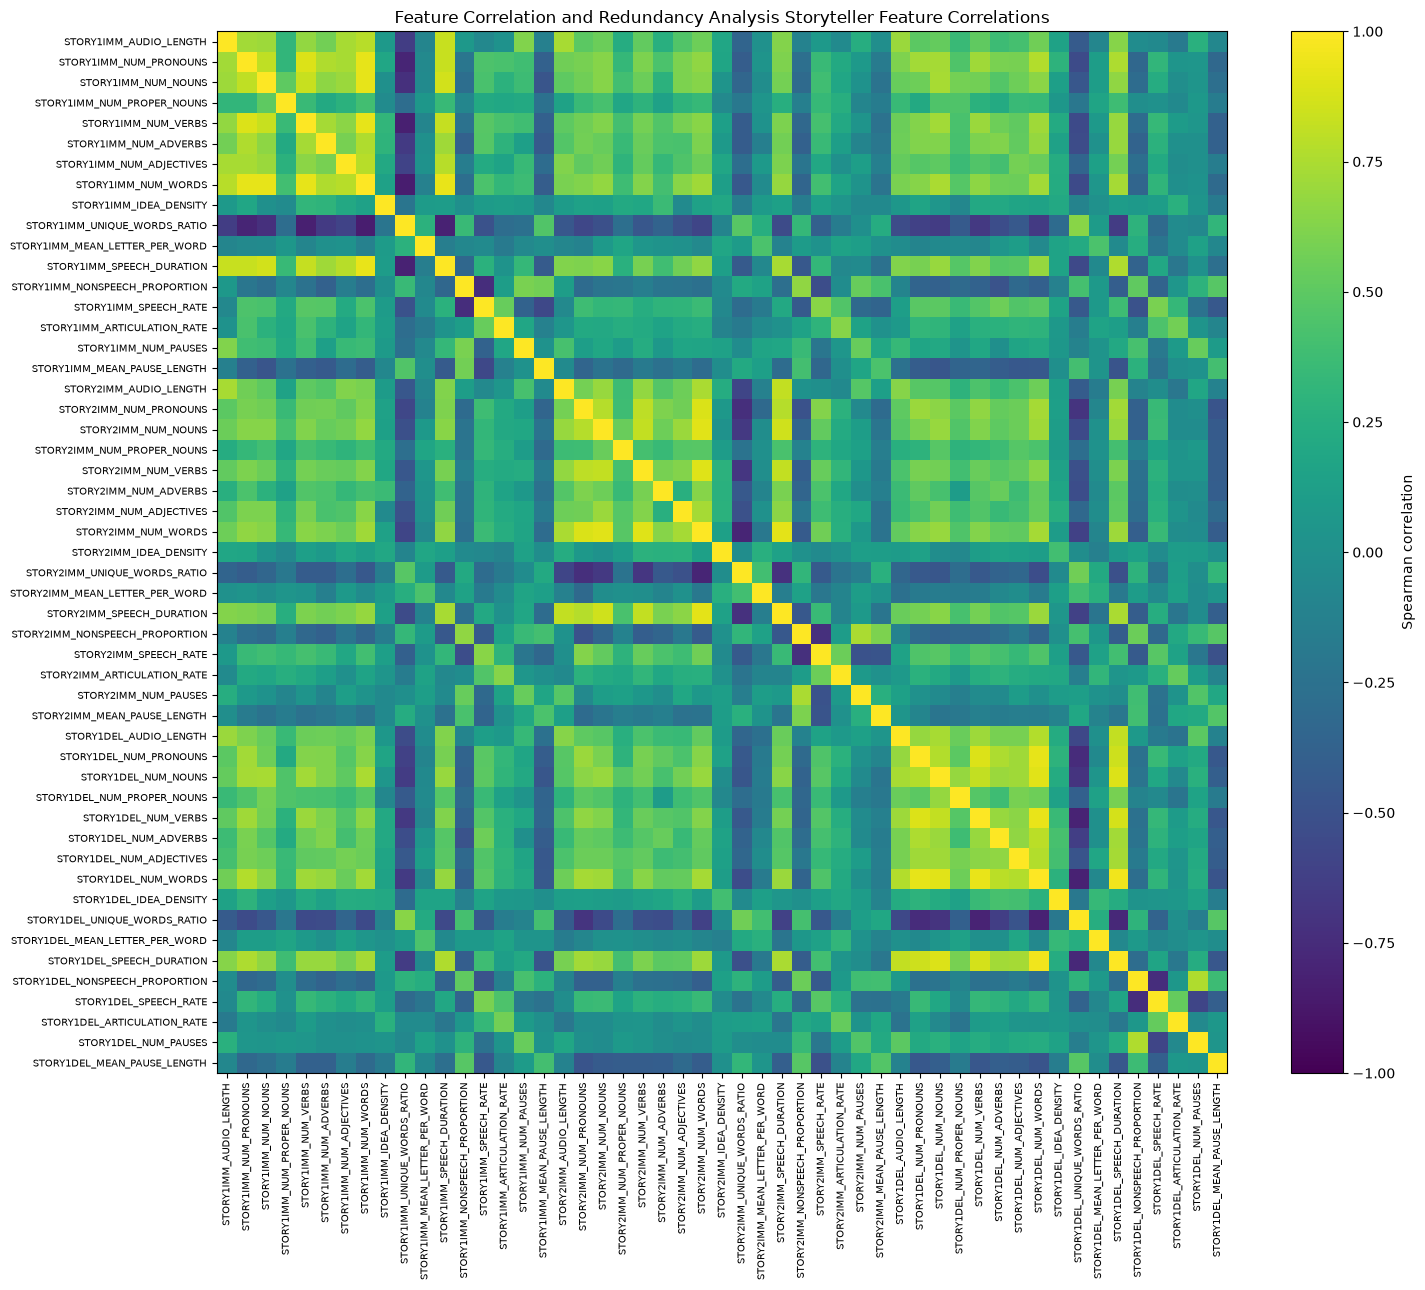

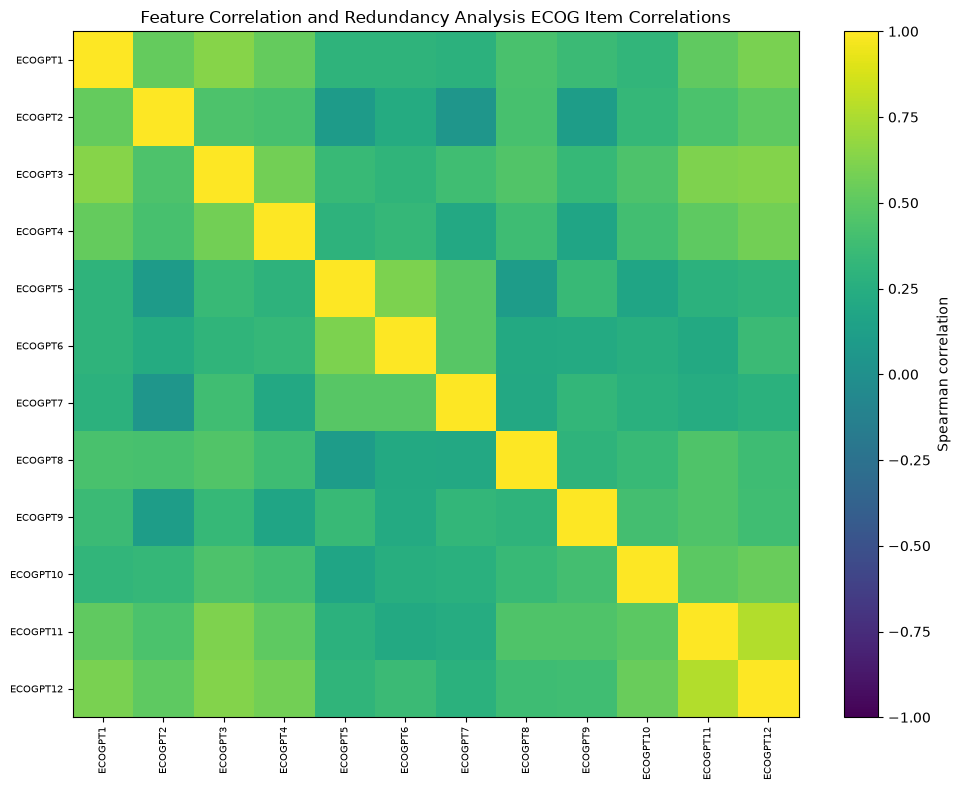

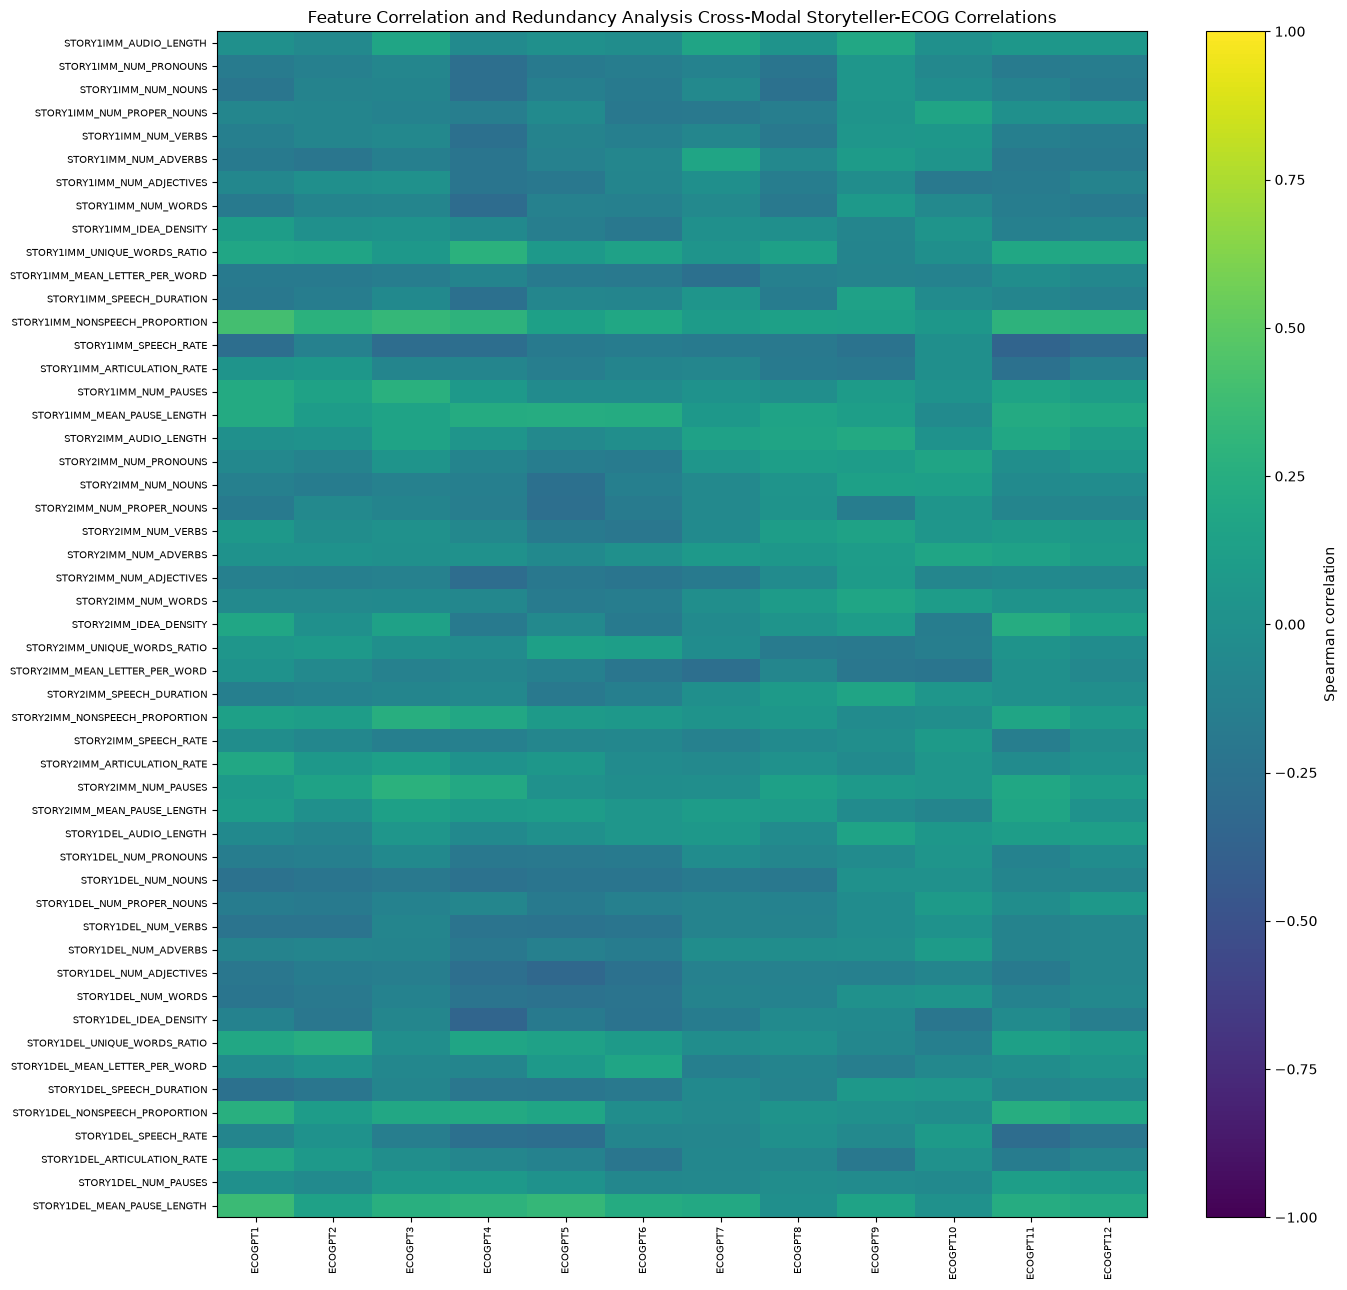


EXPERIMENT 26 COMPLETED
Participants analysed: 71
Interpretation: correlations are estimated on this small fixed cohort and describe association only; lack of high cross-modal correlations does not prove clinical complementarity or feature independence.
Storyteller features: 51
ECOG features: 12
Total valid correlations: 1953
Highly correlated pairs (|Spearman rho| >= 0.7): 99
Highly correlated cross-modal pairs: 0

Results saved to:
c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\results\feature_correlation_redundancy

Important interpretation note:
High correlation indicates statistical association, not interchangeability or proof that a feature is unnecessary. Do not remove features solely on the basis of this analysis.


In [20]:
# Feature Correlation and Redundancy Analysis FEATURE RELATIONSHIP AND REDUNDANCY ANALYSIS
# ============================================================
#
# Purpose:
# 1. Examine correlations among Storyteller features.
# 2. Examine correlations among ECOG items.
# 3. Examine cross-modal Storyteller-ECOG correlations.
# 4. Identify potentially redundant feature pairs.
# 5. Apply Benjamini-Hochberg FDR correction.
#
# Primary analysis: participant-level median aggregation.
# No model training or feature selection is performed.
#
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

RESULTS_DIR = RESULTS_ROOT / "feature_correlation_redundancy"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CORRELATION_THRESHOLD = 0.70
HIGH_CORRELATION_THRESHOLD = 0.85
MIN_PAIRWISE_N = 10
FDR_ALPHA = 0.05

# ------------------------------------------------------------
# 2. CHECK EXISTING EXPERIMENT 24 VARIABLES
# ------------------------------------------------------------

required_variables = [
    "X_story24",
    "X_ecog24",
    "y24",
    "groups24"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing required variables: {missing_variables}. "
        "Run Experiment 24 first."
    )

# Convert feature matrices to DataFrames if necessary.
X_story26 = (
    X_story24.copy()
    if isinstance(X_story24, pd.DataFrame)
    else pd.DataFrame(X_story24)
)

X_ecog26 = (
    X_ecog24.copy()
    if isinstance(X_ecog24, pd.DataFrame)
    else pd.DataFrame(X_ecog24)
)

groups26 = np.asarray(groups24)
y26 = np.asarray(y24)

# ------------------------------------------------------------
# 3. CHECK ROW ALIGNMENT AND FEATURE DIMENSIONS
# ------------------------------------------------------------

if not (
    len(X_story26) == len(X_ecog26)
    == len(groups26) == len(y26)
):
    raise ValueError(
        "X_story24, X_ecog24, y24 and groups24 "
        "do not have the same number of rows."
    )

if not X_story26.index.equals(X_ecog26.index):
    raise ValueError(
        "Storyteller and ECOG DataFrame indices do not match. "
        "Check row alignment before continuing."
    )

# Make feature names unique and readable.
X_story26.columns = [
    str(c) for c in X_story26.columns
]
X_ecog26.columns = [
    str(c) for c in X_ecog26.columns
]

# Convert all features to numeric.
X_story26 = X_story26.apply(pd.to_numeric, errors="coerce")
X_ecog26 = X_ecog26.apply(pd.to_numeric, errors="coerce")

print("=" * 65)
print("Feature Correlation and Redundancy Analysis INITIAL DATA AUDIT")
print("=" * 65)

print("Storyteller assessment rows:", len(X_story26))
print("ECOG assessment rows:", len(X_ecog26))
print("Unique participants:", pd.Series(groups26).nunique())
print("Storyteller features:", X_story26.shape[1])
print("ECOG features:", X_ecog26.shape[1])

# ------------------------------------------------------------
# 4. CREATE PARTICIPANT-LEVEL DATASET
# ------------------------------------------------------------
#
# Each participant contributes one row.
# For participants with repeated assessments, use the median
# of their available feature values.
#
# This prevents participants with more assessments from
# receiving greater weight in the correlation analysis.
# ------------------------------------------------------------

story26_with_id = X_story26.copy()
ecog26_with_id = X_ecog26.copy()

story26_with_id["PTID_GROUP"] = groups26
ecog26_with_id["PTID_GROUP"] = groups26

story_participant26 = (
    story26_with_id
    .groupby("PTID_GROUP")
    .median(numeric_only=True)
)

ecog_participant26 = (
    ecog26_with_id
    .groupby("PTID_GROUP")
    .median(numeric_only=True)
)

# Ensure the same participant order.
common_participants26 = (
    story_participant26.index
    .intersection(ecog_participant26.index)
)

story_participant26 = (
    story_participant26
    .loc[common_participants26]
)

ecog_participant26 = (
    ecog_participant26
    .loc[common_participants26]
)

# Combine feature matrices.
participant_features26 = pd.concat(
    [
        story_participant26,
        ecog_participant26
    ],
    axis=1
)

# ------------------------------------------------------------
# 5. PARTICIPANT-LEVEL DIAGNOSIS CONSISTENCY AUDIT
# ------------------------------------------------------------

diagnosis_data26 = pd.DataFrame({
    "PTID_GROUP": groups26,
    "TARGET": y26
})

diagnosis_counts26 = (
    diagnosis_data26
    .groupby("PTID_GROUP")["TARGET"]
    .nunique()
)

inconsistent_participants26 = (
    diagnosis_counts26[diagnosis_counts26 > 1].index
)

print("\nParticipant-level feature matrix:")
print(participant_features26.shape)

print(
    "Participants with inconsistent labels:",
    len(inconsistent_participants26)
)

if len(inconsistent_participants26) > 0:
    print(
        "WARNING: Some participants have multiple target labels. "
        "They remain in the descriptive feature correlation analysis, "
        "but diagnosis-level summaries will exclude them."
    )

# ------------------------------------------------------------
# 6. FEATURE MISSINGNESS AND VARIABILITY
# ------------------------------------------------------------

feature_audit26 = pd.DataFrame({
    "Feature": participant_features26.columns,
    "Modality": [
        "Storyteller" if c in story_participant26.columns
        else "ECOG"
        for c in participant_features26.columns
    ],
    "Missing_Count": participant_features26.isna().sum().values,
    "Missing_Percentage": (
        participant_features26.isna().mean().values * 100
    ),
    "Unique_Values": [
        participant_features26[c].nunique(dropna=True)
        for c in participant_features26.columns
    ],
    "Standard_Deviation": [
        participant_features26[c].std()
        for c in participant_features26.columns
    ]
})

feature_audit26["Constant_Feature"] = (
    feature_audit26["Unique_Values"] <= 1
)

feature_audit26 = feature_audit26.sort_values(
    ["Modality", "Missing_Percentage"],
    ascending=[True, False]
)

print("\nFEATURE MISSINGNESS AND VARIABILITY")
display(feature_audit26)

# ------------------------------------------------------------
# 7. CORRELATION FUNCTION
# ------------------------------------------------------------

def calculate_pair_correlations26(
    dataframe,
    feature_a,
    feature_b,
    min_n=MIN_PAIRWISE_N
):
    """
    Calculate Pearson and Spearman correlations using
    pairwise complete participant observations.
    """

    pair = dataframe[[feature_a, feature_b]].dropna()
    n = len(pair)

    if n < min_n:
        return None

    x = pair[feature_a].to_numpy(dtype=float)
    y = pair[feature_b].to_numpy(dtype=float)

    if np.std(x) == 0 or np.std(y) == 0:
        return None

    try:
        pearson_r, pearson_p = pearsonr(x, y)
        spearman_r, spearman_p = spearmanr(x, y)

        return {
            "Feature_1": feature_a,
            "Feature_2": feature_b,
            "N_Participants": n,
            "Pearson_r": pearson_r,
            "Pearson_p": pearson_p,
            "Spearman_rho": spearman_r,
            "Spearman_p": spearman_p
        }

    except Exception:
        return None


# ------------------------------------------------------------
# 8. CALCULATE CORRELATIONS FOR ALL FEATURE PAIRS
# ------------------------------------------------------------

def calculate_all_correlations26(
    dataframe,
    feature_list,
    analysis_type
):
    records = []

    feature_list = list(feature_list)

    for i in range(len(feature_list)):
        for j in range(i + 1, len(feature_list)):

            feature_a = feature_list[i]
            feature_b = feature_list[j]

            result = calculate_pair_correlations26(
                dataframe,
                feature_a,
                feature_b
            )

            if result is not None:
                result["Analysis_Type"] = analysis_type
                records.append(result)

    return pd.DataFrame(records)


# Storyteller within-modality correlations.
story_correlations26 = calculate_all_correlations26(
    story_participant26,
    story_participant26.columns,
    "Storyteller-Storyteller"
)

# ECOG within-modality correlations.
ecog_correlations26 = calculate_all_correlations26(
    ecog_participant26,
    ecog_participant26.columns,
    "ECOG-ECOG"
)

# Cross-modal correlations.
cross_correlations26 = []

for story_feature in story_participant26.columns:
    for ecog_feature in ecog_participant26.columns:

        result = calculate_pair_correlations26(
            participant_features26,
            story_feature,
            ecog_feature
        )

        if result is not None:
            result["Analysis_Type"] = "Storyteller-ECOG"
            cross_correlations26.append(result)

cross_correlations26 = pd.DataFrame(
    cross_correlations26
)

# Combine all correlation results.
correlation_results26 = pd.concat(
    [
        story_correlations26,
        ecog_correlations26,
        cross_correlations26
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 9. APPLY BENJAMINI-HOCHBERG FDR CORRECTION
# ------------------------------------------------------------
#
# Correct Pearson and Spearman p-values separately
# across all tested feature pairs.
# ------------------------------------------------------------

if not correlation_results26.empty:

    correlation_results26["Pearson_FDR"] = np.nan
    correlation_results26["Spearman_FDR"] = np.nan

    valid_pearson = (
        correlation_results26["Pearson_p"].notna()
    )

    valid_spearman = (
        correlation_results26["Spearman_p"].notna()
    )

    if valid_pearson.sum() > 0:
        correlation_results26.loc[
            valid_pearson, "Pearson_FDR"
        ] = multipletests(
            correlation_results26.loc[
                valid_pearson, "Pearson_p"
            ],
            method="fdr_bh"
        )[1]

    if valid_spearman.sum() > 0:
        correlation_results26.loc[
            valid_spearman, "Spearman_FDR"
        ] = multipletests(
            correlation_results26.loc[
                valid_spearman, "Spearman_p"
            ],
            method="fdr_bh"
        )[1]

# ------------------------------------------------------------
# 10. IDENTIFY HIGHLY CORRELATED FEATURE PAIRS
# ------------------------------------------------------------

if not correlation_results26.empty:

    correlation_results26["Absolute_Pearson"] = (
        correlation_results26["Pearson_r"].abs()
    )

    correlation_results26["Absolute_Spearman"] = (
        correlation_results26["Spearman_rho"].abs()
    )

    correlation_results26["High_Pearson_Correlation"] = (
        correlation_results26["Absolute_Pearson"]
        >= CORRELATION_THRESHOLD
    )

    correlation_results26["High_Spearman_Correlation"] = (
        correlation_results26["Absolute_Spearman"]
        >= CORRELATION_THRESHOLD
    )

    correlation_results26["Very_High_Pearson_Correlation"] = (
        correlation_results26["Absolute_Pearson"]
        >= HIGH_CORRELATION_THRESHOLD
    )

    correlation_results26["Pearson_FDR_Significant"] = (
        correlation_results26["Pearson_FDR"] < FDR_ALPHA
    )

    correlation_results26["Spearman_FDR_Significant"] = (
        correlation_results26["Spearman_FDR"] < FDR_ALPHA
    )

    correlation_results26 = (
        correlation_results26.sort_values(
            "Absolute_Spearman",
            ascending=False
        )
    )

# ------------------------------------------------------------
# 11. SEPARATE WITHIN-MODALITY AND CROSS-MODAL RESULTS
# ------------------------------------------------------------

high_correlation_pairs26 = (
    correlation_results26[
        (
            correlation_results26["Absolute_Spearman"]
            >= CORRELATION_THRESHOLD
        )
    ].copy()
)

high_correlation_pairs26 = (
    high_correlation_pairs26.sort_values(
        "Absolute_Spearman",
        ascending=False
    )
)

high_cross_modal26 = (
    high_correlation_pairs26[
        high_correlation_pairs26["Analysis_Type"]
        == "Storyteller-ECOG"
    ].copy()
)

high_story_pairs26 = (
    high_correlation_pairs26[
        high_correlation_pairs26["Analysis_Type"]
        == "Storyteller-Storyteller"
    ].copy()
)

high_ecog_pairs26 = (
    high_correlation_pairs26[
        high_correlation_pairs26["Analysis_Type"]
        == "ECOG-ECOG"
    ].copy()
)

# ------------------------------------------------------------
# 12. DISPLAY TOP CORRELATIONS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("Feature Correlation and Redundancy Analysis CORRELATION RESULTS")
print("=" * 65)

print("\nTotal valid feature pairs:", len(correlation_results26))

print(
    "Storyteller-Storyteller pairs:",
    len(story_correlations26)
)

print(
    "ECOG-ECOG pairs:",
    len(ecog_correlations26)
)

print(
    "Storyteller-ECOG pairs:",
    len(cross_correlations26)
)

print(
    "\nPairs with absolute Spearman correlation >= "
    f"{CORRELATION_THRESHOLD}:",
    len(high_correlation_pairs26)
)

print("\nTOP 20 CORRELATED FEATURE PAIRS")
display(
    correlation_results26[
        [
            "Feature_1",
            "Feature_2",
            "Analysis_Type",
            "N_Participants",
            "Pearson_r",
            "Spearman_rho",
            "Spearman_FDR"
        ]
    ].head(20)
)

print("\nHIGH CROSS-MODAL CORRELATIONS")
display(
    high_cross_modal26[
        [
            "Feature_1",
            "Feature_2",
            "N_Participants",
            "Pearson_r",
            "Spearman_rho",
            "Spearman_FDR"
        ]
    ]
)

# ------------------------------------------------------------
# 13. FEATURE-LEVEL REDUNDANCY SUMMARY
# ------------------------------------------------------------
#
# Count how often each feature appears in a highly correlated
# pair. This is descriptive, not an automatic feature-removal rule.
# ------------------------------------------------------------

redundancy_records26 = []

for feature in participant_features26.columns:

    related_pairs = high_correlation_pairs26[
        (
            high_correlation_pairs26["Feature_1"] == feature
        )
        |
        (
            high_correlation_pairs26["Feature_2"] == feature
        )
    ]

    redundancy_records26.append({
        "Feature": feature,
        "Modality": (
            "Storyteller"
            if feature in story_participant26.columns
            else "ECOG"
        ),
        "Number_Highly_Correlated_Pairs": len(related_pairs),
        "Strongest_Absolute_Spearman": (
            related_pairs["Absolute_Spearman"].max()
            if len(related_pairs) > 0
            else 0
        )
    })

redundancy_summary26 = pd.DataFrame(
    redundancy_records26
).sort_values(
    "Number_Highly_Correlated_Pairs",
    ascending=False
)

print("\nFEATURE-LEVEL CORRELATION SUMMARY")
display(redundancy_summary26)

# ------------------------------------------------------------
# 14. CORRELATION MATRICES
# ------------------------------------------------------------

story_spearman_matrix26 = (
    story_participant26.corr(method="spearman")
)

ecog_spearman_matrix26 = (
    ecog_participant26.corr(method="spearman")
)

cross_spearman_matrix26 = pd.DataFrame(
    index=story_participant26.columns,
    columns=ecog_participant26.columns,
    dtype=float
)

for story_feature in story_participant26.columns:
    for ecog_feature in ecog_participant26.columns:

        pair = participant_features26[
            [story_feature, ecog_feature]
        ].dropna()

        if (
            len(pair) >= MIN_PAIRWISE_N
            and pair[story_feature].nunique() > 1
            and pair[ecog_feature].nunique() > 1
        ):
            cross_spearman_matrix26.loc[
                story_feature, ecog_feature
            ] = pair[story_feature].corr(
                pair[ecog_feature],
                method="spearman"
            )

# ------------------------------------------------------------
# 15. PLOT WITHIN-MODALITY CORRELATION HEATMAPS
# ------------------------------------------------------------

def plot_correlation_heatmap26(
    matrix,
    title,
    filename,
    figsize=(12, 10)
):
    fig, ax = plt.subplots(figsize=figsize)

    image = ax.imshow(
        matrix.to_numpy(dtype=float),
        aspect="auto",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(len(matrix.columns)))
    ax.set_xticklabels(
        matrix.columns,
        rotation=90,
        fontsize=7
    )

    ax.set_yticks(range(len(matrix.index)))
    ax.set_yticklabels(
        matrix.index,
        fontsize=7
    )

    ax.set_title(title)
    fig.colorbar(
        image,
        ax=ax,
        label="Spearman correlation"
    )

    plt.tight_layout()
    plt.savefig(
        RESULTS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


plot_correlation_heatmap26(
    story_spearman_matrix26,
    "Feature Correlation and Redundancy Analysis Storyteller Feature Correlations",
    "feature_correlation_redundancy_storyteller_correlation_heatmap.png",
    figsize=(15, 13)
)

plot_correlation_heatmap26(
    ecog_spearman_matrix26,
    "Feature Correlation and Redundancy Analysis ECOG Item Correlations",
    "feature_correlation_redundancy_ecog_correlation_heatmap.png",
    figsize=(10, 8)
)

plot_correlation_heatmap26(
    cross_spearman_matrix26,
    "Feature Correlation and Redundancy Analysis Cross-Modal Storyteller-ECOG Correlations",
    "feature_correlation_redundancy_cross_modal_correlation_heatmap.png",
    figsize=(14, 13)
)

# ------------------------------------------------------------
# 16. SAVE ALL RESULTS
# ------------------------------------------------------------

participant_features26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_participant_features.csv"
)

feature_audit26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_feature_audit.csv",
    index=False
)

correlation_results26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_all_correlations.csv",
    index=False
)

high_correlation_pairs26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_high_correlation_pairs.csv",
    index=False
)

high_cross_modal26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_high_cross_modal_pairs.csv",
    index=False
)

redundancy_summary26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_feature_redundancy_summary.csv",
    index=False
)

story_spearman_matrix26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_storyteller_spearman_matrix.csv"
)

ecog_spearman_matrix26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_ecog_spearman_matrix.csv"
)

cross_spearman_matrix26.to_csv(
    RESULTS_DIR / "feature_correlation_redundancy_cross_modal_spearman_matrix.csv"
)

# ------------------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT 26 COMPLETED")
print("=" * 65)

print("Participants analysed:", len(participant_features26))
print(
    "Interpretation: correlations are estimated on this small fixed cohort "
    "and describe association only; lack of high cross-modal correlations "
    "does not prove clinical complementarity or feature independence."
)
print("Storyteller features:", len(story_participant26.columns))
print("ECOG features:", len(ecog_participant26.columns))

print(
    "Total valid correlations:",
    len(correlation_results26)
)

print(
    "Highly correlated pairs (|Spearman rho| >= "
    f"{CORRELATION_THRESHOLD}):",
    len(high_correlation_pairs26)
)

print(
    "Highly correlated cross-modal pairs:",
    len(high_cross_modal26)
)

print("\nResults saved to:")
print(RESULTS_DIR)

print("\nImportant interpretation note:")
print(
    "High correlation indicates statistical association, not "
    "interchangeability or proof that a feature is unnecessary. "
    "Do not remove features solely on the basis of this analysis."
)


# ============================================================


# ============================================================

# ============================================================


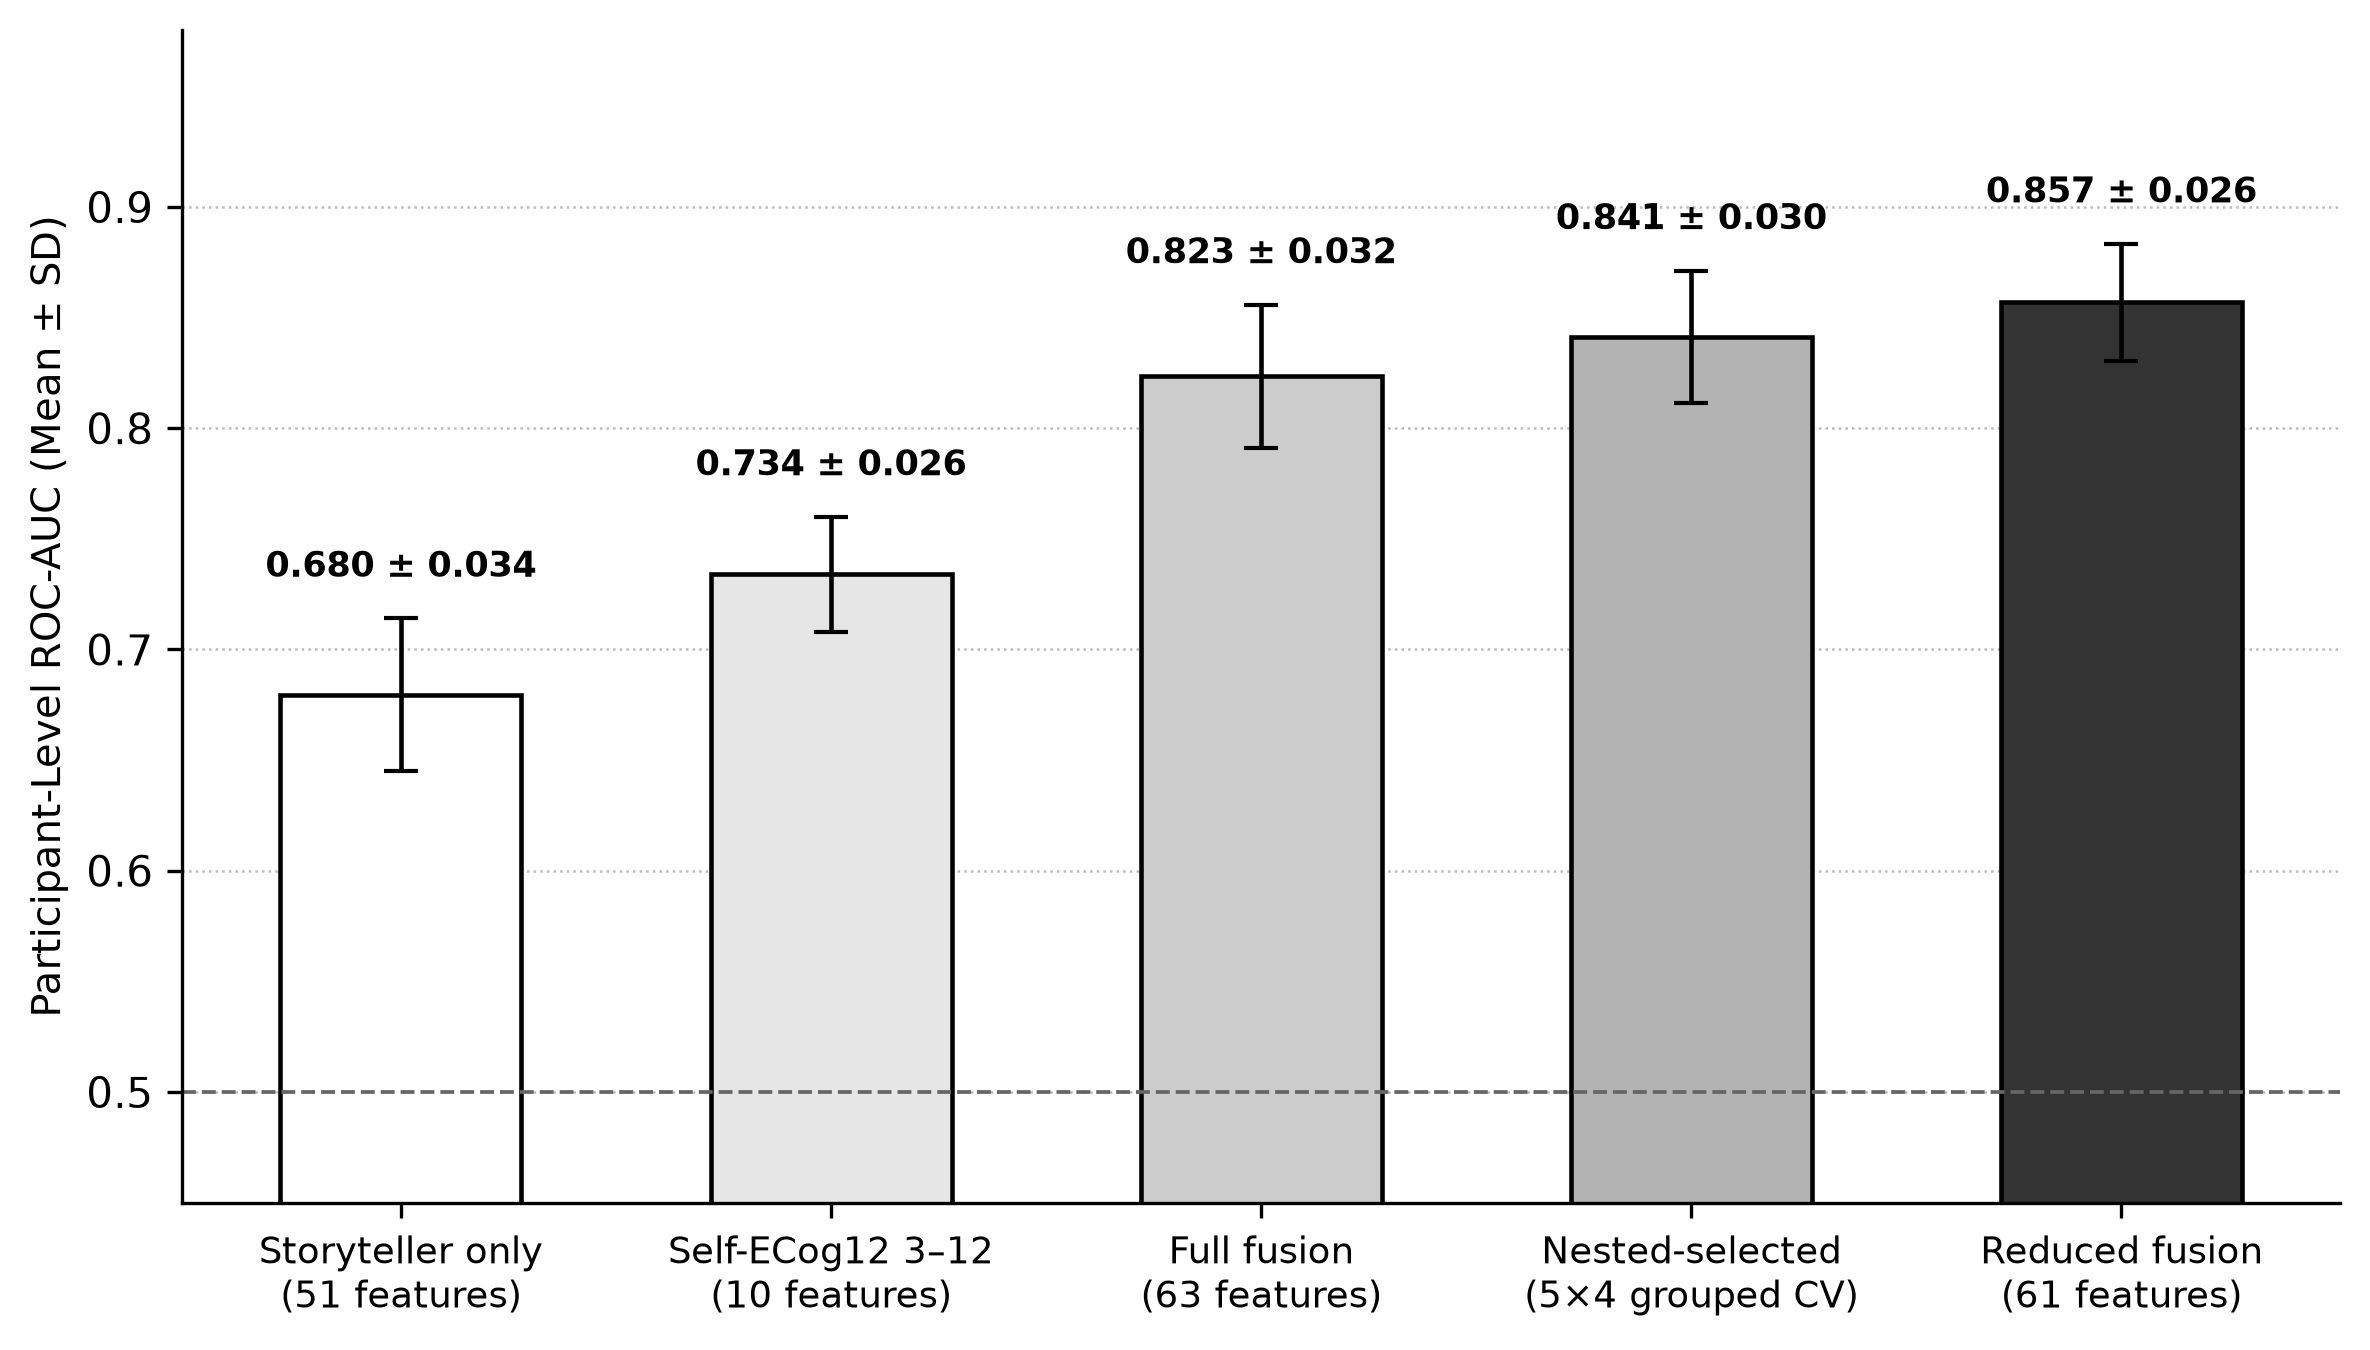

Saved Figure 2 to: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\figures\Figure2_Primary_ROC_AUC_Comparison.png


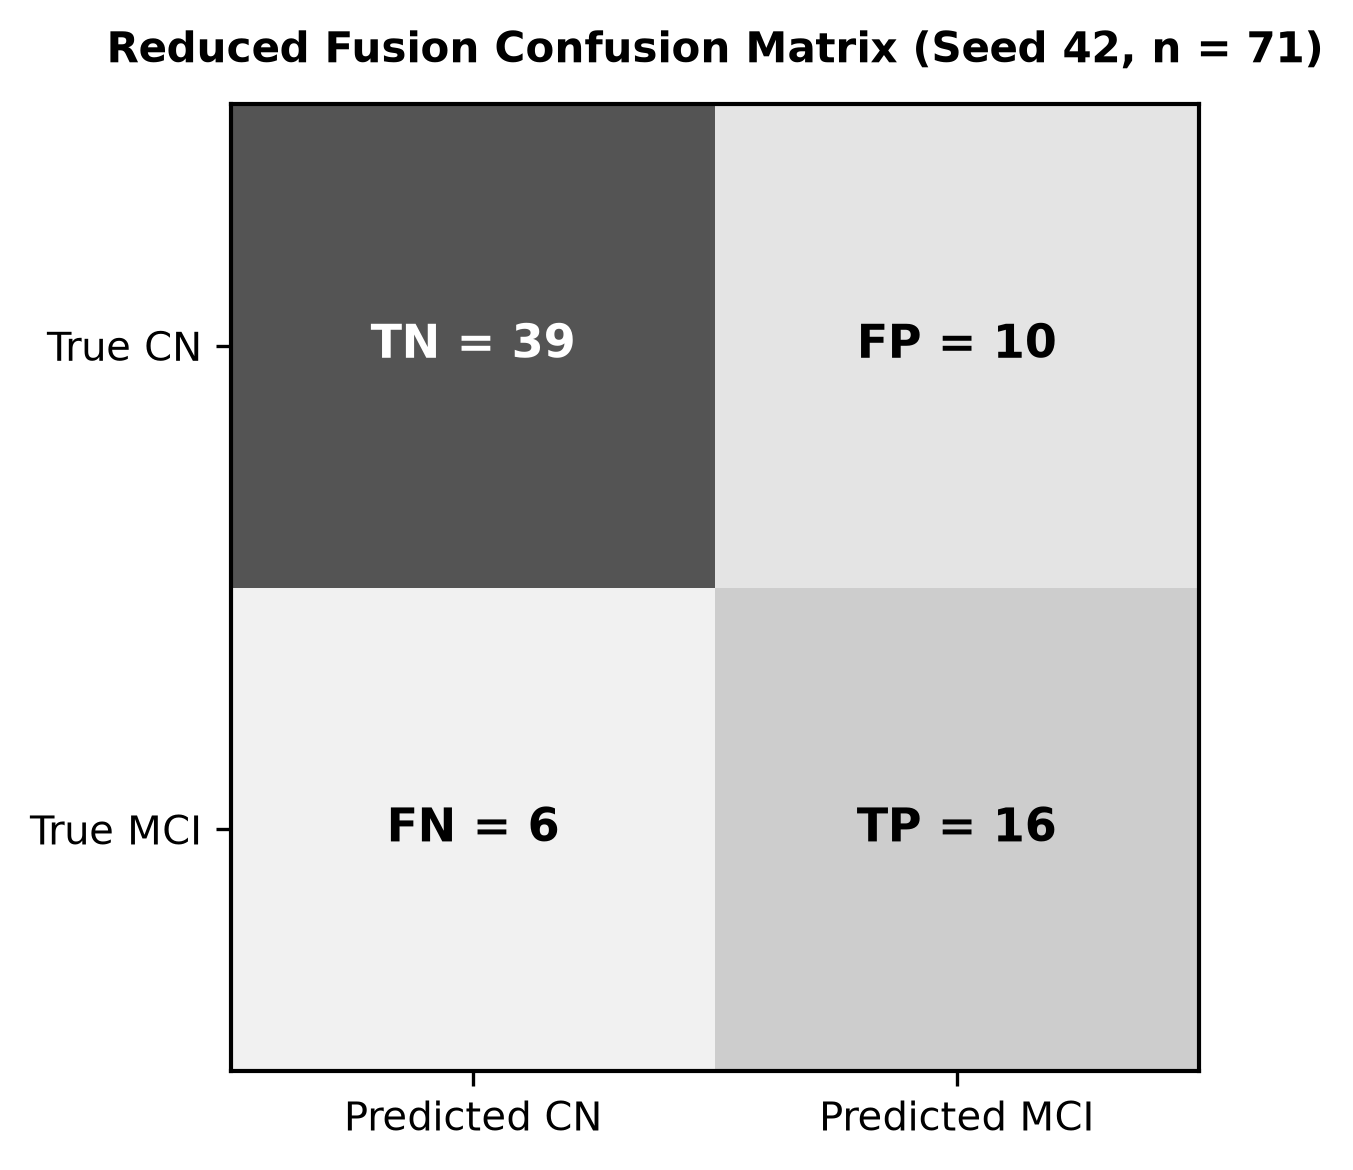

Saved Figure 3A to: c:\Users\amnar\Documents\ADNI4_Storyteller_ECOG_Classification\figures\Figure3A_Reduced_Fusion_Confusion_Matrix.png


In [22]:
# ============================================================
# FIGURE 2 (ROC-AUC) & FIGURE 3A (CONFUSION MATRIX)
# Uses in-memory variables from this notebook (no Dataset 4 overlap)
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES_ROOT = PROJECT_DIR / "figures"
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams["font.family"] = "DejaVu Sans"

# --- Figure 2: 10-Seed Participant-Level ROC-AUC (from modality_stability24) ---
plot_items = [
    ("Storyteller only\n(51 features)",
     float(modality_stability24.loc["Storyteller only", ("ROC_AUC", "mean")]),
     float(modality_stability24.loc["Storyteller only", ("ROC_AUC", "std")])),
    ("Self-ECog12 3–12\n(10 features)",
     float(modality_stability24.loc["ECOG only (items 3-12)", ("ROC_AUC", "mean")]),
     float(modality_stability24.loc["ECOG only (items 3-12)", ("ROC_AUC", "std")])),
    ("Full fusion\n(63 features)",
     float(modality_stability24.loc["Full fusion", ("ROC_AUC", "mean")]),
     float(modality_stability24.loc["Full fusion", ("ROC_AUC", "std")])),
]

# Optional: include Nested-selected bar from notebook 03 if already saved
nested_csv = RESULTS_ROOT / "nested_feature_selection" / "nested_feature_selection_participant_summary.csv"
if nested_csv.is_file():
    nested_df = pd.read_csv(nested_csv)
    nested_row = nested_df.loc[nested_df["Model"] == "Nested_selected"].iloc[0]
    plot_items.append((
        "Nested-selected\n(5×4 grouped CV)",
        float(nested_row["ROC_AUC_mean"]),
        float(nested_row["ROC_AUC_std"]),
    ))

plot_items.append((
    "Reduced fusion\n(61 features)",
    float(modality_stability24.loc["Reduced fusion (without items 1 and 2)", ("ROC_AUC", "mean")]),
    float(modality_stability24.loc["Reduced fusion (without items 1 and 2)", ("ROC_AUC", "std")]),
))

labels = [x[0] for x in plot_items]
means = [x[1] for x in plot_items]
sds = [x[2] for x in plot_items]
bar_fills = ["#FFFFFF", "#E6E6E6", "#CCCCCC", "#B3B3B3", "#333333"][:len(labels)]
bar_fills[-1] = "#333333"

fig, ax = plt.subplots(figsize=(8.0, 4.6), dpi=300)
x = np.arange(len(labels))
ax.bar(
    x, means, yerr=sds, width=0.56,
    color=bar_fills, edgecolor="#000000", linewidth=1.1,
    capsize=4, error_kw={"elinewidth": 1.1, "ecolor": "#000000"},
)

for xi, m, s in zip(x, means, sds):
    ax.text(xi, m + s + 0.015, f"{m:.3f} ± {s:.3f}", ha="center", va="bottom",
            fontsize=8.5, fontweight="bold", color="#000000")

ax.axhline(0.50, color="#666666", linestyle="--", linewidth=0.9)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=8.8, color="#000000")
ax.set_ylabel("Participant-Level ROC-AUC (Mean ± SD)", fontsize=9.5, color="#000000")
ax.set_ylim(0.45, 0.98)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle=":", linewidth=0.6, color="#BBBBBB")
ax.set_axisbelow(True)

fig2_path = FIGURES_ROOT / "Figure2_Primary_ROC_AUC_Comparison.png"
plt.tight_layout()
plt.savefig(fig2_path, dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.show()
print("Saved Figure 2 to:", fig2_path)

# --- Figure 3A: Seed-42 Confusion Matrix (from confusion_comparison23) ---
cm_row = confusion_comparison23.loc[
    confusion_comparison23["Model"] == "Fusion without ECOGPT1 and ECOGPT2"
].iloc[0]
tn, fp, fn, tp = int(cm_row["TN"]), int(cm_row["FP"]), int(cm_row["FN"]), int(cm_row["TP"])
cm = np.array([[tn, fp], [fn, tp]])
cell_labels = [["TN", "FP"], ["FN", "TP"]]

fig, ax = plt.subplots(figsize=(4.4, 4.0), dpi=300)
ax.imshow(cm, cmap="Greys", vmin=0, vmax=max(cm.max() * 1.35, 1))

for i in range(2):
    for j in range(2):
        val = cm[i, j]
        txt_color = "#FFFFFF" if val > cm.max() * 0.70 else "#000000"
        ax.text(j, i, f"{cell_labels[i][j]} = {val}", ha="center", va="center",
                fontsize=11, fontweight="bold", color=txt_color)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Predicted CN", "Predicted MCI"], fontsize=9.5, color="#000000")
ax.set_yticklabels(["True CN", "True MCI"], fontsize=9.5, color="#000000")
ax.set_title("Reduced Fusion Confusion Matrix (Seed 42, n = 71)", fontsize=10.2, fontweight="bold", pad=10)
for spine in ax.spines.values():
    spine.set_edgecolor("#000000")
    spine.set_linewidth(1.0)

fig3a_path = FIGURES_ROOT / "Figure3A_Reduced_Fusion_Confusion_Matrix.png"
plt.tight_layout()
plt.savefig(fig3a_path, dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.show()
print("Saved Figure 3A to:", fig3a_path)